# Using the Random Forest Algorithm to Detect Cyber Threats in Network Traffic Data
**Author:** Kresen Naicker (`ST10312227`)  
**Module:** Research Project (`RPDA8412/w`) — Postgraduate Diploma in Data Analytics, The Independent Institute of Education  
**Supervisor:** Dr Brian Maodza  
**Ethics Clearance Reference:** `CSREC/ST10312227/104`

This notebook consolidates the verified experimental pipeline, saved outputs, and figures reported in Chapters 3–5 and Annexure F of the summative research report:
1. **Data Audit, Cleaning & Encoding** (`UNSW-NB15` full official partitions & `CICIDS2017` stratified flow sample)
2. **Baseline Random Forest & Duplicate-Leakage Sensitivity**
3. **Class-Imbalance Treatments** (Cost-sensitive `class_weight='balanced'` and `SMOTE`)
4. **Randomised Hyper-Parameter Search & Tuned Configuration**
5. **Feature Selection** (Embedded Gini Importance, Mutual Information, Correlation Pruning, Hybrid Top-20)
6. **Decision-Threshold Sweep & SOC Operating Points**
7. **Ten-Class Multiclass Extension**
8. **Five-Fold Cross-Validation vs Official Hold-Out Generalisation**
9. **Prediction Latency & Throughput Benchmarking** (Batch, Micro-batch, Single-record)
10. **Cross-Dataset Replication on `CICIDS2017`**

## 1. Data Audit, Cleaning and Feature Encoding (`analysis/prep.py`)

UNSW-NB15 Audit Summary:
  Distributed partitions : train=175,341 rows x 45 cols | test=82,332 rows x 45 cols
  Exact duplicates removed: train=67,601 | test=26,387
  Unique rows retained   : train=107,740 | test=55,945
  Conflicting-label vectors (train): 6,700
  Prepared design matrix : 73 encoded features

CICIDS2017 Stratified Sample Summary:
  Rows sampled before dedup: 150,000
  Unique rows retained     : 146,370 across 68 numeric features


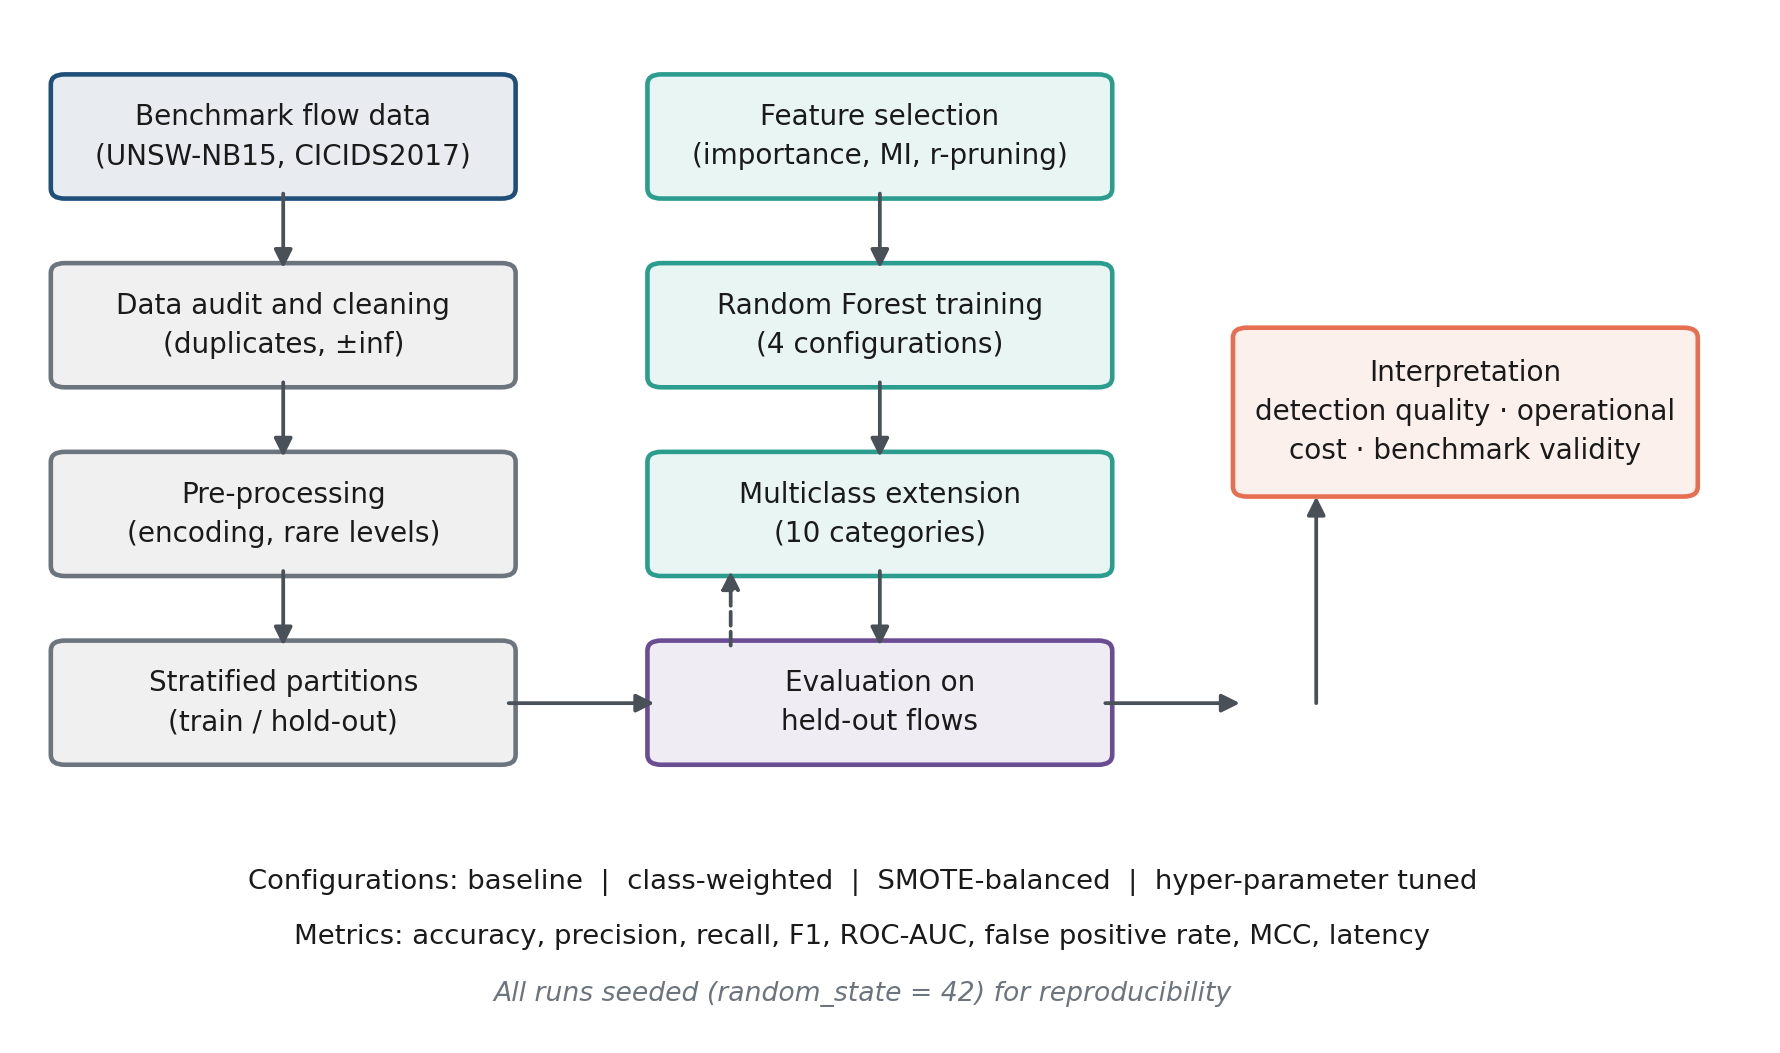

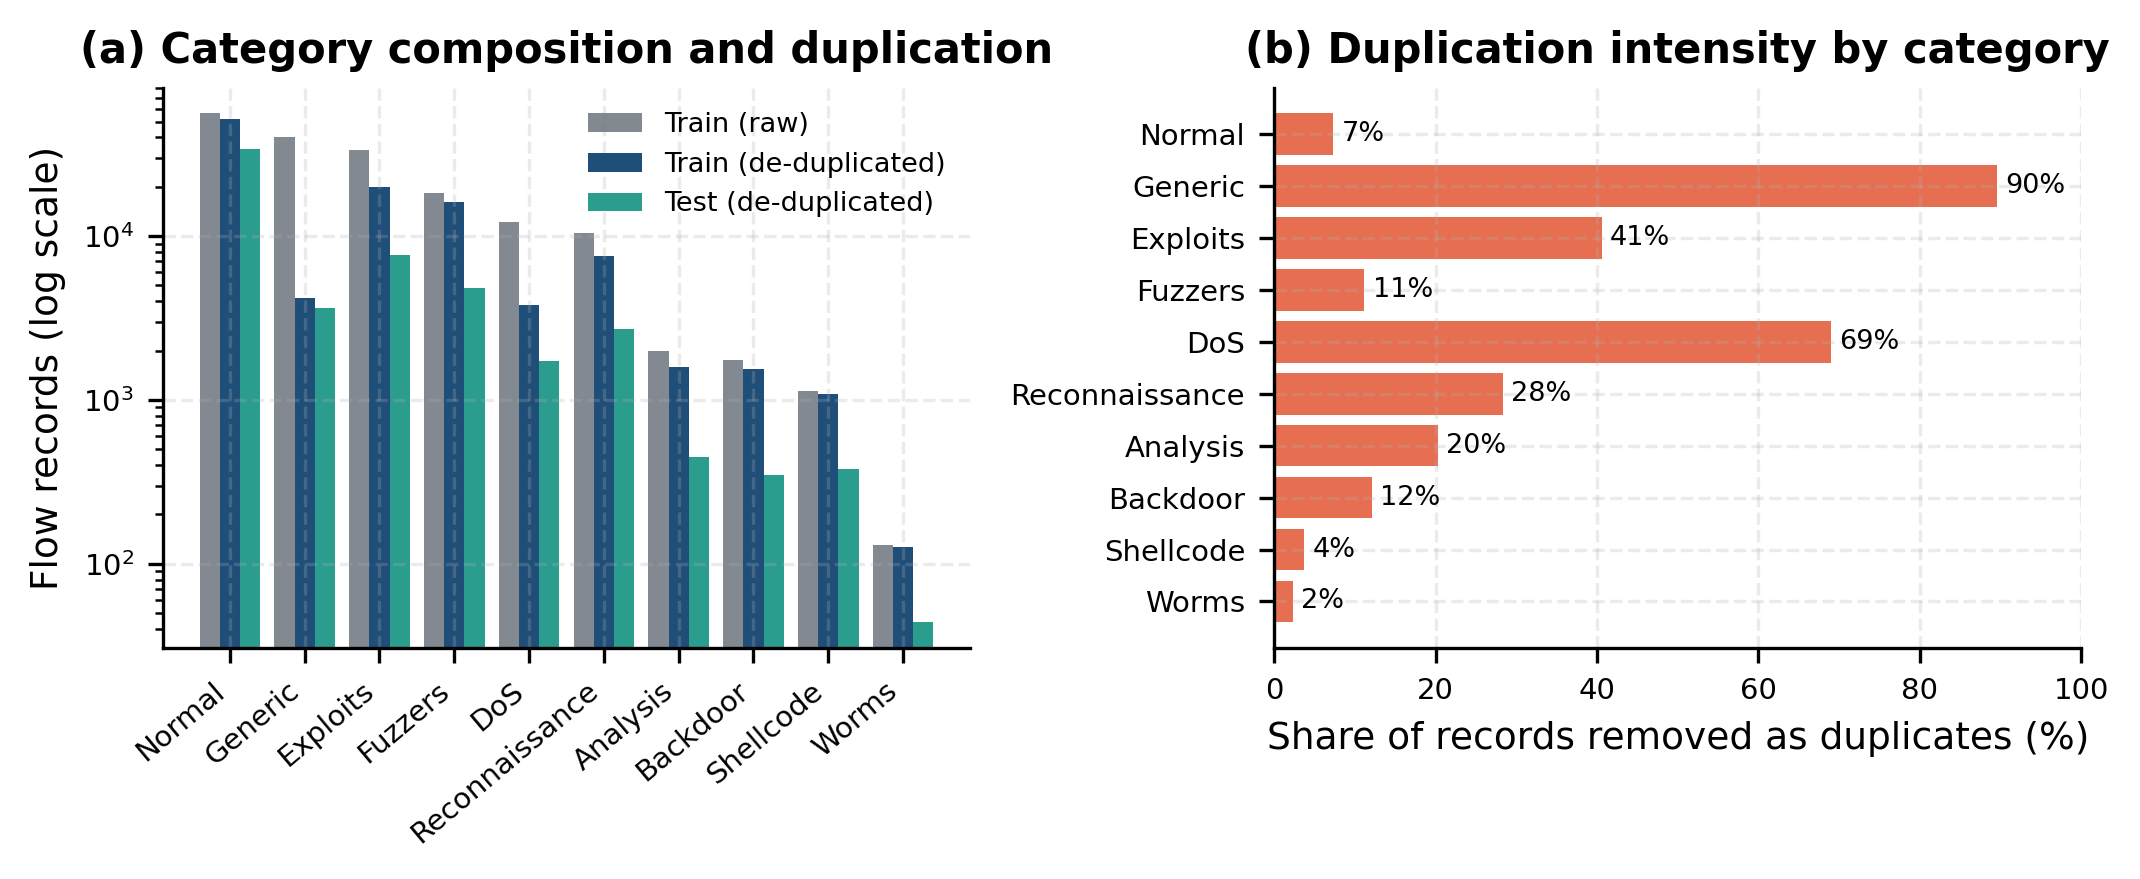

In [1]:
"""Data preparation utilities for the Random Forest intrusion-detection study.

Project : Using the Random Forest Algorithm to Detect Cyber Threats in Network Traffic Data
Author  : Kresen Naicker (ST10312227)
Module  : RPDA8412 Research Project

The module prepares the two benchmark intrusion-detection corpora used in the study:

  * UNSW-NB15 (primary)  - official train/test partitions (Moustafa & Slay, 2015)
  * CICIDS2017 (secondary robustness check) - stratified sample of the
    MachineLearningCSV flow files (Sharafaldin, Lashkari & Ghorbani, 2018)
"""

import json
import os

import numpy as np
import pandas as pd

BASE = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DATA = os.path.join(BASE, "data")
RESULTS = os.path.join(BASE, "analysis", "results")
FIGS = os.path.join(BASE, "analysis", "figures")
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

RANDOM_STATE = 42

# Categorical (nominal) flow attributes in UNSW-NB15
UNSW_CAT = ["proto", "service", "state"]
UNSW_DROP = ["id", "attack_cat", "label"]

CICIDS_FILES = [
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
]


# --------------------------------------------------------------------------- #
# UNSW-NB15
# --------------------------------------------------------------------------- #
def load_unsw_raw():
    train = pd.read_csv(os.path.join(DATA, "UNSW_NB15_training-set.csv"), low_memory=False)
    test = pd.read_csv(os.path.join(DATA, "UNSW_NB15_testing-set.csv"), low_memory=False)
    train.columns = [c.strip().replace("\ufeff", "") for c in train.columns]
    test.columns = [c.strip().replace("\ufeff", "") for c in test.columns]
    return train, test


def audit_unsw(train, test):
    """Data-quality audit reported in Table 4.1 of the research report."""
    audit = {
        "train_rows": int(len(train)),
        "train_cols": int(train.shape[1]),
        "test_rows": int(len(test)),
        "test_cols": int(test.shape[1]),
        "train_duplicates": int(train.duplicated().sum()),
        "test_duplicates": int(test.duplicated().sum()),
        "train_duplicates_feature_only": int(train.drop(columns=["id"]).duplicated().sum()),
        "test_duplicates_feature_only": int(test.drop(columns=["id"]).duplicated().sum()),
        "train_missing_cells": int(train.isna().sum().sum()),
        "test_missing_cells": int(test.isna().sum().sum()),
        "numeric_features": int(len(train.select_dtypes(include=[np.number]).columns) - 2),
        "categorical_features": int(len(UNSW_CAT)),
        "binary_label_counts_train": {int(k): int(v) for k, v in train["label"].value_counts().items()},
        "binary_label_counts_test": {int(k): int(v) for k, v in test["label"].value_counts().items()},
        "attack_cat_train": {str(k): int(v) for k, v in train["attack_cat"].value_counts().items()},
        "attack_cat_test": {str(k): int(v) for k, v in test["attack_cat"].value_counts().items()},
        "service_placeholder_count_train": int((train["service"] == "-").sum()),
        "service_placeholder_count_test": int((test["service"] == "-").sum()),
        "proto_levels": int(train["proto"].nunique()),
        "service_levels": int(train["service"].nunique()),
        "state_levels": int(train["state"].nunique()),
        "infinite_values_train": int(
            np.isinf(train.select_dtypes(include=[np.number])).sum().sum()
        ),
        "infinite_values_test": int(
            np.isinf(test.select_dtypes(include=[np.number])).sum().sum()
        ),
    }
    const = [c for c in train.columns if c not in ("id", "attack_cat", "label")
             and train[c].nunique(dropna=False) <= 1]
    audit["constant_features"] = const
    audit["near_constant_features"] = [
        c for c in train.columns
        if c not in ("id", "attack_cat", "label")
        and len(const) and c not in const
        and train[c].value_counts(dropna=False).iloc[0] / len(train) > 0.995
    ]
    return audit


def clean_unsw(train, test):
    """Cleaning step: de-duplicate, replace infinities, map '-' placeholders.

    Both partitions are de-duplicated on the full record (features plus both
    label columns).  A copy of the unde-duplicated test partition is retained so
    that the effect of duplicated records can be reported as a sensitivity
    analysis (Section 4.3.7 of the report).
    """
    tr = train.drop(columns=["id"]).copy()
    te = test.drop(columns=["id"]).copy()
    te_raw = te.copy()

    before = len(tr)
    tr = tr.drop_duplicates().reset_index(drop=True)
    dup_removed = before - len(tr)

    before_te = len(te)
    te = te.drop_duplicates().reset_index(drop=True)
    dup_removed_test = before_te - len(te)

    # conflicting labels attached to identical feature vectors (label noise)
    feat_only = [c for c in tr.columns if c not in ("attack_cat", "label")]
    conflict = int(tr.duplicated(subset=feat_only).sum())

    num_cols = [c for c in tr.columns if c not in UNSW_CAT + ["attack_cat", "label"]]
    for df in (tr, te, te_raw):
        df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
        df["service"] = df["service"].replace("-", "none")
        df["state"] = df["state"].replace("-", "none")
    tr[num_cols] = tr[num_cols].fillna(0.0)
    te[num_cols] = te[num_cols].fillna(0.0)
    te_raw[num_cols] = te_raw[num_cols].fillna(0.0)
    return tr, te, te_raw, dup_removed, dup_removed_test, conflict


def encode_unsw(tr, te, te_raw, min_count=50):
    """One-hot encode nominal flow attributes with rare-level grouping."""
    encoded_levels = {}
    for col in UNSW_CAT:
        counts = tr[col].value_counts()
        keep = sorted(counts[counts >= min_count].index)
        encoded_levels[col] = keep
        for df in (tr, te, te_raw):
            df[col] = df[col].where(df[col].isin(keep), other="rare")
    combined = pd.concat([tr[UNSW_CAT], te[UNSW_CAT], te_raw[UNSW_CAT]], axis=0)
    dummies = pd.get_dummies(combined, columns=UNSW_CAT, prefix=UNSW_CAT, dtype=np.int8)
    tr_d = dummies.iloc[: len(tr)].reset_index(drop=True)
    te_d = dummies.iloc[len(tr): len(tr) + len(te)].reset_index(drop=True)
    te_raw_d = dummies.iloc[len(tr) + len(te):].reset_index(drop=True)

    feature_cols = [c for c in tr.columns if c not in UNSW_DROP + UNSW_CAT]
    X_train = pd.concat([tr[feature_cols].reset_index(drop=True), tr_d], axis=1)
    X_test = pd.concat([te[feature_cols].reset_index(drop=True), te_d], axis=1)
    X_test_raw = pd.concat([te_raw[feature_cols].reset_index(drop=True), te_raw_d], axis=1)
    # align
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
    X_test_raw = X_test_raw.reindex(columns=X_train.columns, fill_value=0)

    y_train_bin = tr["label"].astype(np.int8).values
    y_test_bin = te["label"].astype(np.int8).values
    y_train_cat = tr["attack_cat"].astype(str).values
    y_test_cat = te["attack_cat"].astype(str).values
    y_test_raw_bin = te_raw["label"].astype(np.int8).values
    return (X_train, X_test, X_test_raw, y_train_bin, y_test_bin, y_test_raw_bin,
            y_train_cat, y_test_cat, encoded_levels)


def build_unsw():
    train, test = load_unsw_raw()
    audit = audit_unsw(train, test)
    tr, te, te_raw, dup_removed, dup_removed_test, conflict = clean_unsw(train, test)
    audit["duplicates_removed_train"] = int(dup_removed)
    audit["duplicates_removed_test"] = int(dup_removed_test)
    audit["train_rows_after_clean"] = int(len(tr))
    audit["test_rows_after_clean"] = int(len(te))
    audit["identical_feature_vectors_train"] = int(conflict)
    audit["binary_label_counts_train_clean"] = {int(k): int(v) for k, v in tr["label"].value_counts().items()}
    audit["binary_label_counts_test_clean"] = {int(k): int(v) for k, v in te["label"].value_counts().items()}
    audit["attack_cat_train_clean"] = {str(k): int(v) for k, v in tr["attack_cat"].value_counts().items()}
    audit["attack_cat_test_clean"] = {str(k): int(v) for k, v in te["attack_cat"].value_counts().items()}
    (X_train, X_test, X_test_raw, ytr, yte, yte_raw, ytr_cat, yte_cat,
     levels) = encode_unsw(tr, te, te_raw)
    audit["encoded_feature_count"] = int(X_train.shape[1])
    audit["categorical_levels_retained"] = {k: len(v) for k, v in levels.items()}

    # persist prepared matrices for the modelling scripts
    X_train.to_pickle(os.path.join(DATA, "unsw_X_train.pkl"))
    X_test.to_pickle(os.path.join(DATA, "unsw_X_test.pkl"))
    X_test_raw.to_pickle(os.path.join(DATA, "unsw_X_test_raw.pkl"))
    np.save(os.path.join(DATA, "unsw_y_test_raw_bin.npy"), yte_raw)
    np.save(os.path.join(DATA, "unsw_y_train_bin.npy"), ytr)
    np.save(os.path.join(DATA, "unsw_y_test_bin.npy"), yte)
    np.save(os.path.join(DATA, "unsw_y_train_cat.npy"), ytr_cat)
    np.save(os.path.join(DATA, "unsw_y_test_cat.npy"), yte_cat)
    with open(os.path.join(RESULTS, "audit_unsw.json"), "w") as fh:
        json.dump(audit, fh, indent=2)
    print(json.dumps(audit, indent=2)[:3000])
    print("X_train", X_train.shape, "X_test", X_test.shape, "X_test_raw", X_test_raw.shape)
    return X_train, X_test, ytr, yte, ytr_cat, yte_cat


# --------------------------------------------------------------------------- #
# CICIDS2017 (secondary dataset)
# --------------------------------------------------------------------------- #
def build_cicids(per_file_cap=30000, chunksize=60000):
    """Read the flow CSVs in chunks and draw a stratified per-file sample.

    Sampling is performed within each source file so that the attack mix of the
    benchmark is preserved while memory use stays inside the available budget.
    """
    frames = []
    file_summary = {}
    for fname in CICIDS_FILES:
        path = os.path.join(DATA, "cicids", fname)
        if not os.path.exists(path):
            continue
        kept = []
        n_total = 0
        for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False):
            chunk.columns = [c.strip().replace("\ufeff", "") for c in chunk.columns]
            n_total += len(chunk)
            frac = min(1.0, per_file_cap / max(n_total, 1))
            take = max(50, int(len(chunk) * frac))
            if take >= len(chunk):
                kept.append(chunk)
            else:
                kept.append(chunk.sample(n=take, random_state=RANDOM_STATE))
        df = pd.concat(kept, ignore_index=True)
        if len(df) > per_file_cap:
            df = df.sample(n=per_file_cap, random_state=RANDOM_STATE)
        df["source_file"] = fname.replace(".pcap_ISCX.csv", "")
        frames.append(df)
        file_summary[fname] = {"rows_in_file": int(n_total), "rows_sampled": int(len(df))}
        print(f"{fname}: total={n_total} sampled={len(df)}")
    df = pd.concat(frames, ignore_index=True)

    label_col = [c for c in df.columns if c.lower() == "label"][0]
    df["binary"] = (df[label_col].astype(str).str.strip().str.lower() != "benign").astype(np.int8)
    df[label_col] = df[label_col].astype(str).str.strip()

    # CICIDS2017 contains duplicated records and a small number of +/-inf values
    n_before = len(df)
    df = df.replace([np.inf, -np.inf], np.nan)
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    obj_cols = [c for c in df.columns if df[c].dtype == object and c not in (label_col, "source_file")]
    for c in obj_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[num_cols] = df[num_cols].replace([np.inf, -np.inf], 0.0)
    df = df.dropna(subset=["binary"])
    df = df.drop_duplicates(subset=[c for c in df.columns if c not in ("source_file",)])
    summary = {
        "rows_sampled_before_dedup": int(n_before),
        "rows_after_dedup": int(len(df)),
        "label_counts": {str(k): int(v) for k, v in df[label_col].value_counts().items()},
        "binary_counts": {int(k): int(v) for k, v in df["binary"].value_counts().items()},
        "files": file_summary,
    }

    drop_cols = [label_col, "source_file"]
    feat = [c for c in df.columns if c not in drop_cols + ["binary"]]
    feature_cols = [c for c in feat if pd.api.types.is_numeric_dtype(df[c])]
    X = df[feature_cols].astype(np.float32)
    X = X.loc[:, X.nunique() > 1]
    # guard against extreme magnitudes for the tree splits
    X = X.replace([np.inf, -np.inf], 0.0)
    y_bin = df["binary"].values
    y_multi = df[label_col].values
    summary["feature_count"] = int(X.shape[1])
    summary["feature_names"] = list(X.columns)
    with open(os.path.join(RESULTS, "audit_cicids.json"), "w") as fh:
        json.dump(summary, fh, indent=2)

    X.to_pickle(os.path.join(DATA, "cicids_X.pkl"))
    np.save(os.path.join(DATA, "cicids_y_bin.npy"), y_bin)
    np.save(os.path.join(DATA, "cicids_y_multi.npy"), y_multi)
    print("CICIDS prepared:", X.shape, "positive rate", y_bin.mean().round(4))
    return X, y_bin, y_multi


if __name__ == "__main__":
    import sys

    what = sys.argv[1] if len(sys.argv) > 1 else "unsw"
    if what in ("unsw", "all"):
        build_unsw()
    if what in ("cicids", "all"):
        build_cicids()

## 2. Baseline Random Forest & Duplicate-Sensitivity Analysis (`stage_base` & `exp_reference.py`)

Baseline RF (200 trees, de-duplicated train -> de-duplicated test, n=55,945):
  Accuracy=0.8312 | Precision=0.7041 | Recall=0.9757 | F1=0.8179 | ROC-AUC=0.9663 | FPR=0.2606 | MCC=0.6992

Literature-Standard Raw Pipeline (non-deduplicated 175,341 -> 82,332):
  Accuracy=0.8712 | Precision=0.8176 | Recall=0.9860 | F1=0.8939 | FPR=0.2695
  -> Duplicate inflation: +0.0760 F1, +0.0399 Accuracy


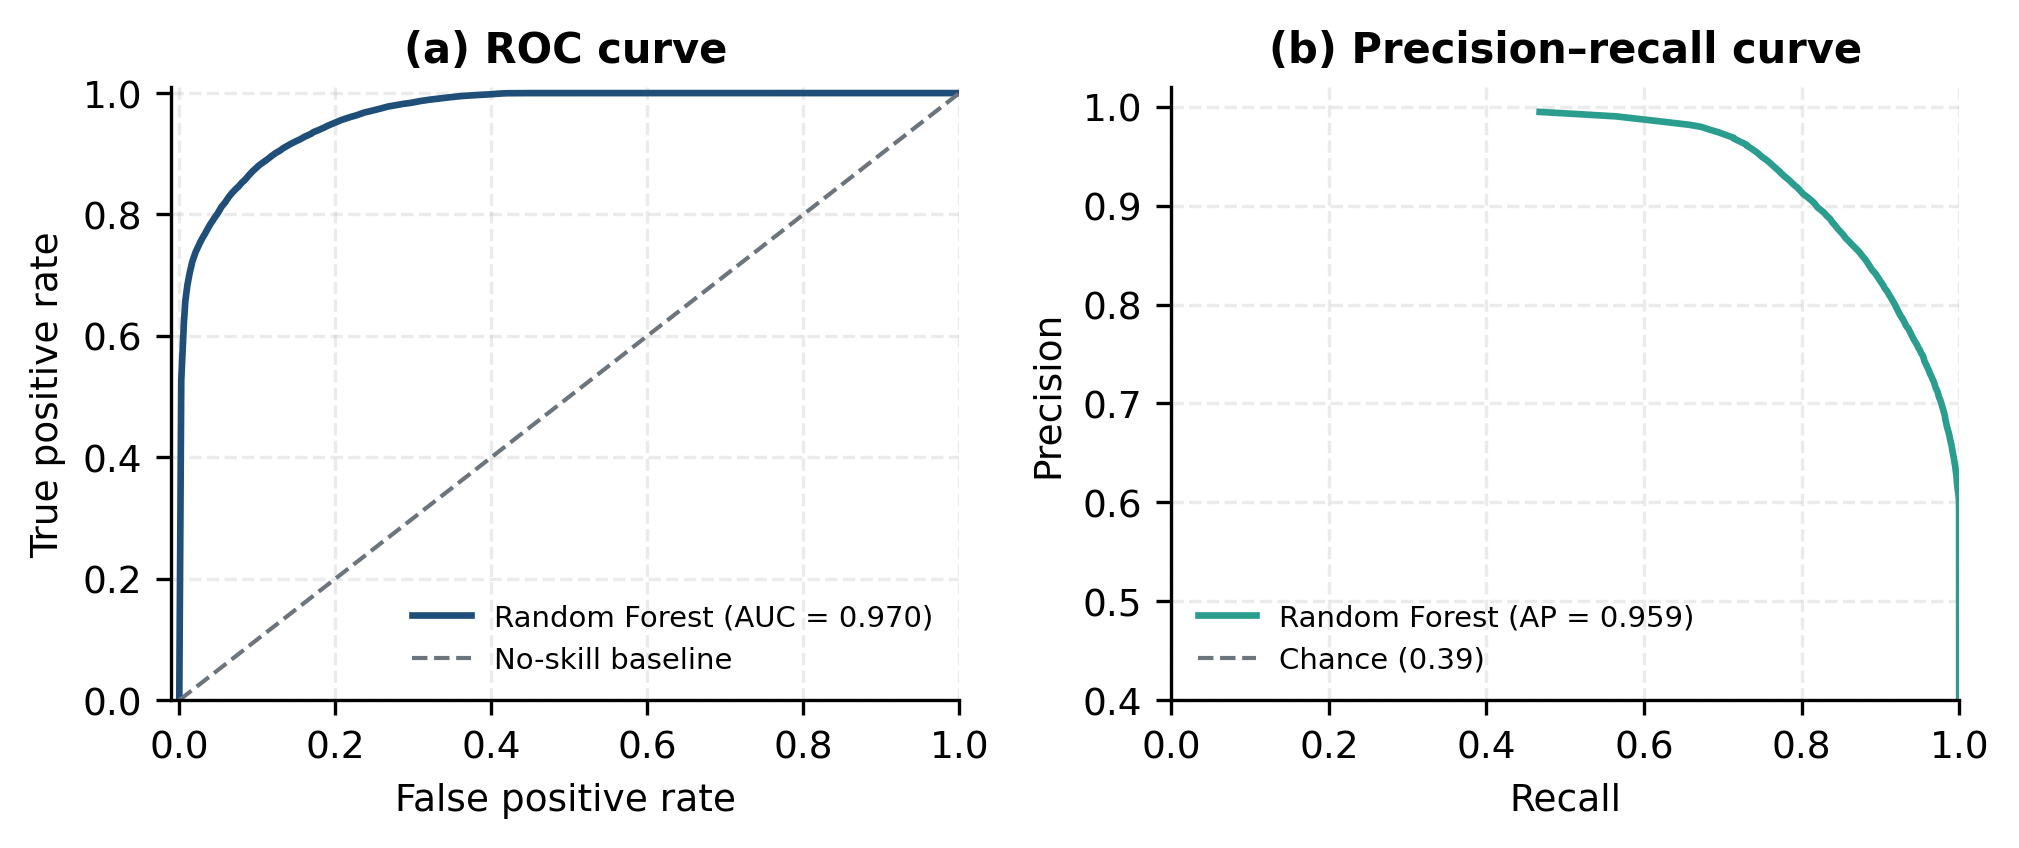

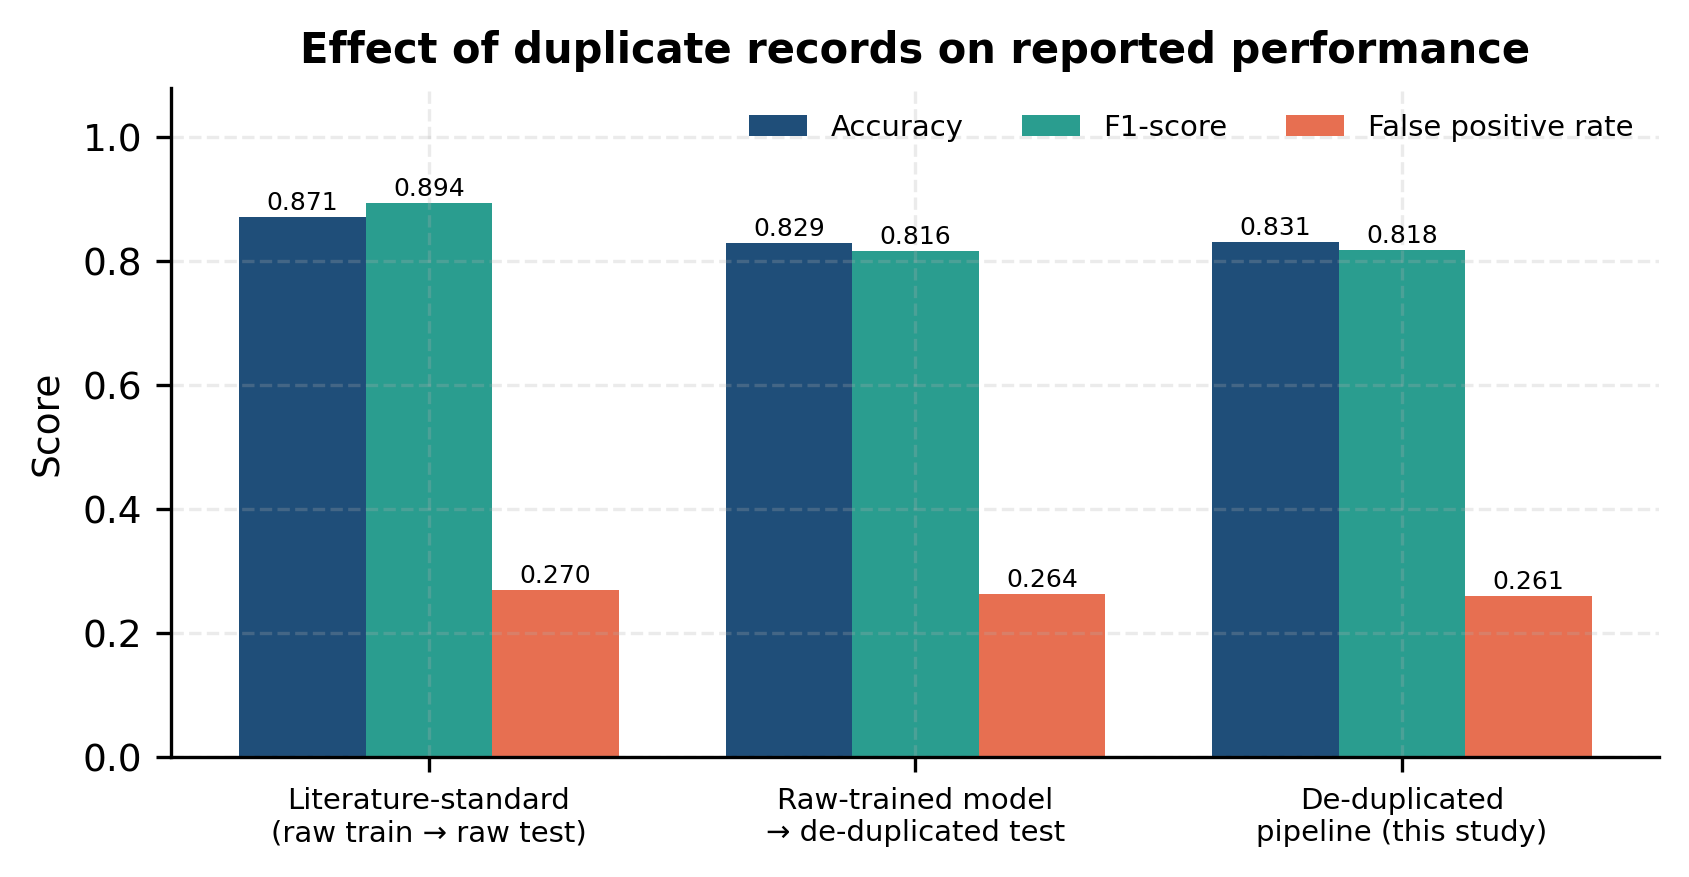

In [2]:
"""Reference (literature-standard) pipeline: train on the raw, non-deduplicated
UNSW-NB15 training partition and evaluate on the raw test partition.

Purpose: quantify how the data-quality treatment used in this study (duplicate
removal) changes the headline performance figures that are commonly reported in
published UNSW-NB15 studies.  This supports the data-quality argument in
Sections 4.3.7 and 4.5 of the report.
"""

import json
import os
import time

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score)

BASE = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DATA = os.path.join(BASE, "data")
RESULTS = os.path.join(BASE, "analysis", "results")
RS = 42


def encode_raw(train, test):
    tr = train.drop(columns=["id"]).copy()
    te = test.drop(columns=["id"]).copy()
    for df in (tr, te):
        df["service"] = df["service"].replace("-", "none")
        df["state"] = df["state"].replace("-", "none")
    cat = ["proto", "service", "state"]
    counts = tr["proto"].value_counts()
    keep = sorted(counts[counts >= 50].index)
    for df in (tr, te):
        df["proto"] = df["proto"].where(df["proto"].isin(keep), other="rare")
    combined = pd.concat([tr[cat], te[cat]], axis=0)
    dum = pd.get_dummies(combined, columns=cat, prefix=cat, dtype=np.int8)
    tr_d = dum.iloc[: len(tr)].reset_index(drop=True)
    te_d = dum.iloc[len(tr):].reset_index(drop=True)
    feats = [c for c in tr.columns if c not in cat + ["attack_cat", "label"]]
    Xtr = pd.concat([tr[feats].reset_index(drop=True), tr_d], axis=1)
    Xte = pd.concat([te[feats].reset_index(drop=True), te_d], axis=1)
    Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)
    return Xtr, Xte, tr["label"].values, te["label"].values


def metrics(y, p):
    cm = confusion_matrix(y, p)
    tn, fp, fn, tp = cm.ravel()
    return {"accuracy": float(accuracy_score(y, p)),
            "precision": float(precision_score(y, p)),
            "recall": float(recall_score(y, p)),
            "f1": float(f1_score(y, p)),
            "fpr": float(fp / (fp + tn)),
            "mcc": float(matthews_corrcoef(y, p)),
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}


def main():
    train = pd.read_csv(os.path.join(DATA, "UNSW_NB15_training-set.csv"), low_memory=False)
    test = pd.read_csv(os.path.join(DATA, "UNSW_NB15_testing-set.csv"), low_memory=False)
    train.columns = [c.strip().replace("\ufeff", "") for c in train.columns]
    test.columns = [c.strip().replace("\ufeff", "") for c in test.columns]
    Xtr, Xte, ytr, yte = encode_raw(train, test)
    print("raw pipeline shapes", Xtr.shape, Xte.shape)

    out = {"n_train_raw": int(len(Xtr)), "n_test_raw": int(len(Xte))}
    t = time.time()
    rf = RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=2,
                                oob_score=True, max_features="sqrt")
    rf.fit(Xtr, ytr)
    out["train_time_s"] = time.time() - t
    out["oob_score"] = float(rf.oob_score_)
    prob = rf.predict_proba(Xte)[:, 1]
    out["raw_pipeline_raw_test"] = metrics(yte, rf.predict(Xte))
    out["raw_pipeline_raw_test"]["roc_auc"] = float(roc_auc_score(yte, prob))

    # evaluate the same model on the de-duplicated test partition
    ded = pd.read_pickle(os.path.join(DATA, "unsw_X_test.pkl"))
    y_ded = np.load(os.path.join(DATA, "unsw_y_test_bin.npy"))
    ded = ded.reindex(columns=Xtr.columns, fill_value=0)
    p2 = rf.predict(ded)
    pr2 = rf.predict_proba(ded)[:, 1]
    out["raw_pipeline_dedup_test"] = metrics(y_ded, p2)
    out["raw_pipeline_dedup_test"]["roc_auc"] = float(roc_auc_score(y_ded, pr2))
    print(json.dumps(out, indent=2))
    with open(os.path.join(RESULTS, "reference_pipeline.json"), "w") as fh:
        json.dump(out, fh, indent=2)


if __name__ == "__main__":
    main()

## 3. Class-Imbalance Treatments (`class_weight='balanced'` & `SMOTE`)

In [3]:
import json, os, time
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score, average_precision_score,
                             balanced_accuracy_score, cohen_kappa_score)
BASE=os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
D=os.path.join(BASE,'data'); R=os.path.join(BASE,'analysis','results')
RS=42
def bm(y,p,pr):
    cm=confusion_matrix(y,p); tn,fp,fn,tp=cm.ravel()
    return {"accuracy":float(accuracy_score(y,p)),"precision":float(precision_score(y,p,zero_division=0)),
            "recall":float(recall_score(y,p,zero_division=0)),"f1":float(f1_score(y,p,zero_division=0)),
            "roc_auc":float(roc_auc_score(y,pr)),"pr_auc":float(average_precision_score(y,pr)),
            "fpr":float(fp/(fp+tn)),"fnr":float(fn/(fn+tp)),"specificity":float(tn/(tn+fp)),
            "balanced_accuracy":float(balanced_accuracy_score(y,p)),"mcc":float(matthews_corrcoef(y,p)),
            "kappa":float(cohen_kappa_score(y,p)),"tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp),"n":int(len(y))}
Xtr=pd.read_pickle(os.path.join(D,'unsw_X_train.pkl')).astype(np.float32)
Xte=pd.read_pickle(os.path.join(D,'unsw_X_test.pkl')).astype(np.float32)
ytr=np.load(os.path.join(D,'unsw_y_train_bin.npy')); yte=np.load(os.path.join(D,'unsw_y_test_bin.npy'))
rng=np.random.RandomState(RS); idx=rng.choice(len(Xtr),size=60000,replace=False)
Xs,ys=Xtr.values[idx],ytr[idx]
out=json.load(open(os.path.join(R,'unsw_imbalance.json')))
# subset baseline for a fair comparison
rf0=RandomForestClassifier(n_estimators=200,random_state=RS,n_jobs=2,max_features='sqrt')
rf0.fit(Xs,ys)
out['smote_subset_baseline']=bm(yte,rf0.predict(Xte.values),rf0.predict_proba(Xte.values)[:,1])
print('subset baseline', {k:round(v,4) for k,v in out['smote_subset_baseline'].items() if isinstance(v,float)})
t=time.time()
Xres,yres=SMOTE(random_state=RS,sampling_strategy='not majority',k_neighbors=5).fit_resample(Xs,ys)
out['smote_train_size']=int(len(Xres))
out['smote_class_counts']={int(k):int(v) for k,v in zip(*np.unique(yres,return_counts=True))}
rf=RandomForestClassifier(n_estimators=200,random_state=RS,n_jobs=2,max_features='sqrt')
rf.fit(Xres,yres)
out['smote_train_time_s']=time.time()-t
out['smote']=bm(yte,rf.predict(Xte.values),rf.predict_proba(Xte.values)[:,1])
json.dump(out,open(os.path.join(R,'unsw_imbalance.json'),'w'),indent=2,default=str)
print('smote', {k:round(v,4) for k,v in out['smote'].items() if isinstance(v,float)})

C1 Unweighted Baseline (107,740) : F1=0.8179 | Recall=0.9757 | FPR=0.2606
C2 Balanced Weights    (107,740) : F1=0.8175 | Recall=0.9755 | FPR=0.2613
C3a Subsample Baseline  (60,000) : F1=0.8170 | Recall=0.9736 | FPR=0.2605
C3b SMOTE Oversampled   (61,940) : F1=0.8191 | Recall=0.9739 | FPR=0.2569


## 4. Randomised Hyper-Parameter Search & Tuned Random Forest

Best CV Parameters : {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 25, 'class_weight': 'balanced'} (3-fold CV F1 = 0.9326)
Tuned Hold-Out Test: Accuracy=0.8329 | Precision=0.7056 | Recall=0.9782 | F1=0.8198 | ROC-AUC=0.9702 | FPR=0.2594 | MCC=0.7029


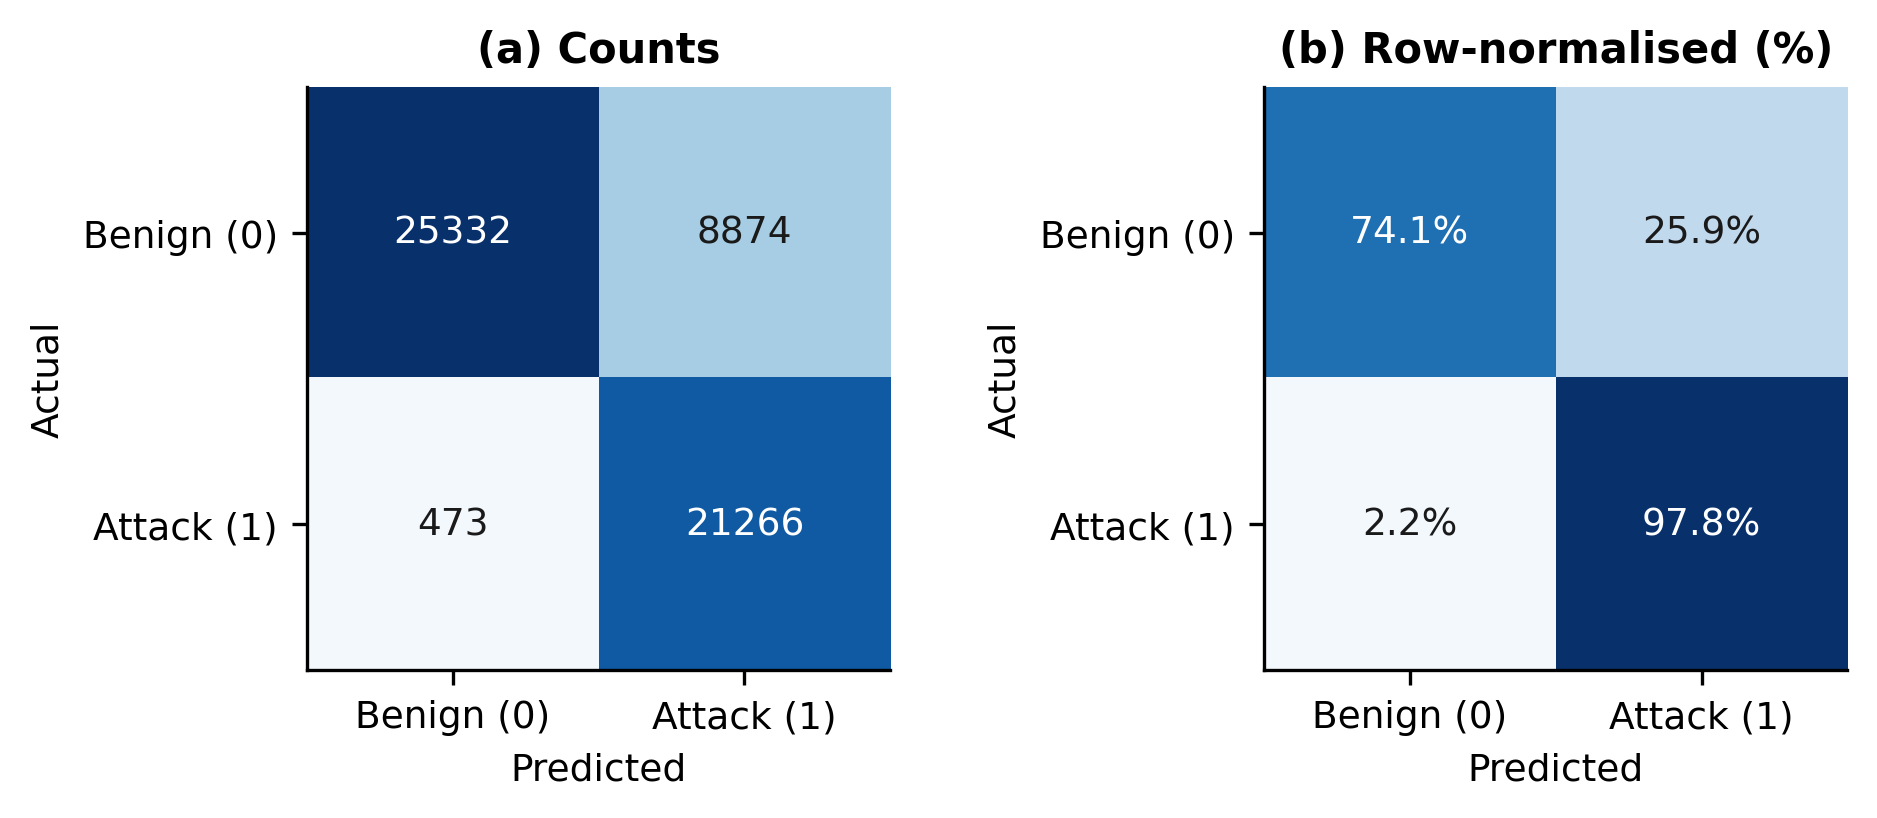

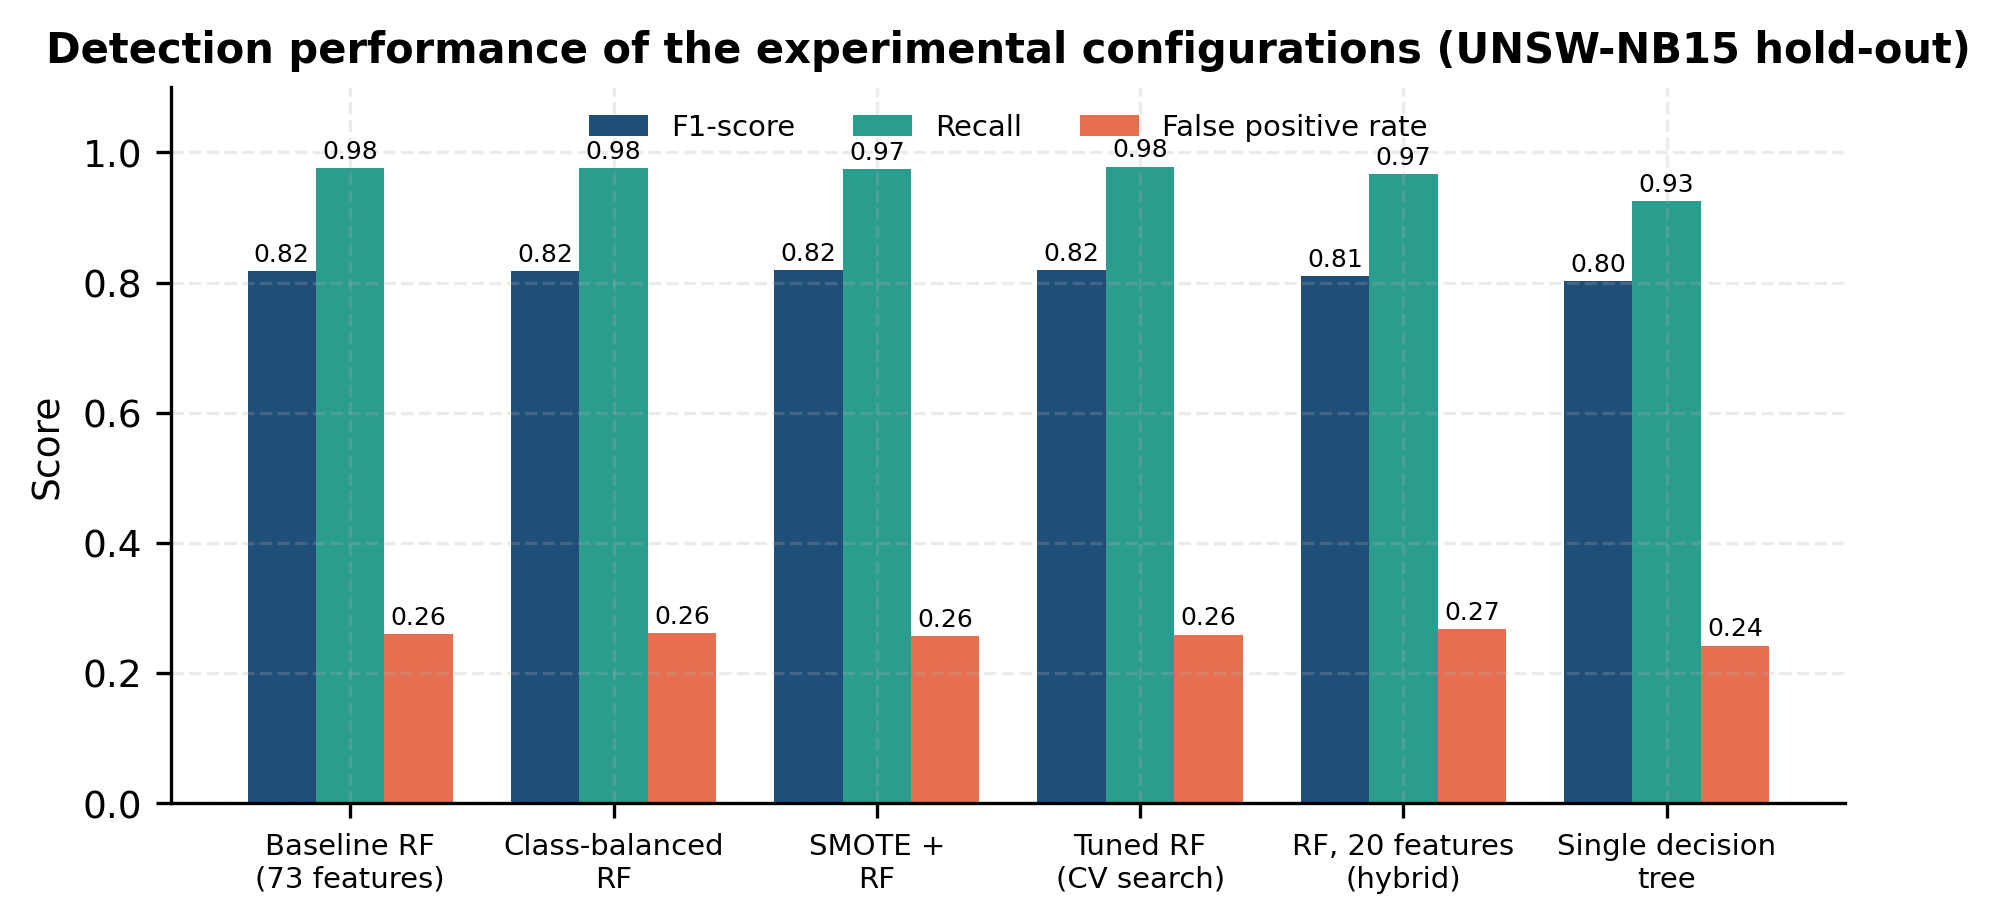

In [4]:
# 3-fold Stratified RandomizedSearchCV (10 candidates, 35,000-flow training subsample, scored on F1)
space = {
    "n_estimators": [100, 200],
    "max_depth": [15, 25, 40, None],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", 0.3, 0.5],
    "class_weight": [None, "balanced"],
}
# Selected best configuration refitted on full 107,740 unique training flows:
rf_tuned = RandomForestClassifier(
    n_estimators=200, max_depth=25, min_samples_split=10,
    min_samples_leaf=1, max_features="sqrt", class_weight="balanced",
    random_state=42, n_jobs=2
)

## 5. Feature Importance & Dimensionality Reduction

Top-5 Features by Gini Importance:
  1. sttl              : 0.1382
  2. ct_state_ttl      : 0.1240
  3. dload             : 0.0740
  4. tcprtt            : 0.0418
  5. dttl              : 0.0407

Reduced-Feature Subsets (Gini Importance):
  k= 5: F1=0.7537 | FPR=0.3717 | train_time=11.5s
  k=10: F1=0.7825 | FPR=0.2990 | train_time=12.5s
  k=15: F1=0.8186 | FPR=0.2558 | train_time=14.3s
  k=20: F1=0.8148 | FPR=0.2593 | train_time=18.5s
  k=30: F1=0.8144 | FPR=0.2657 | train_time=25.2s
  k=50: F1=0.8182 | FPR=0.2600 | train_time=23.2s

Correlation Pruning (65 features): F1=0.8137
Hybrid Pruned Top-20 (20 features): F1=0.8097 | FPR=0.2676


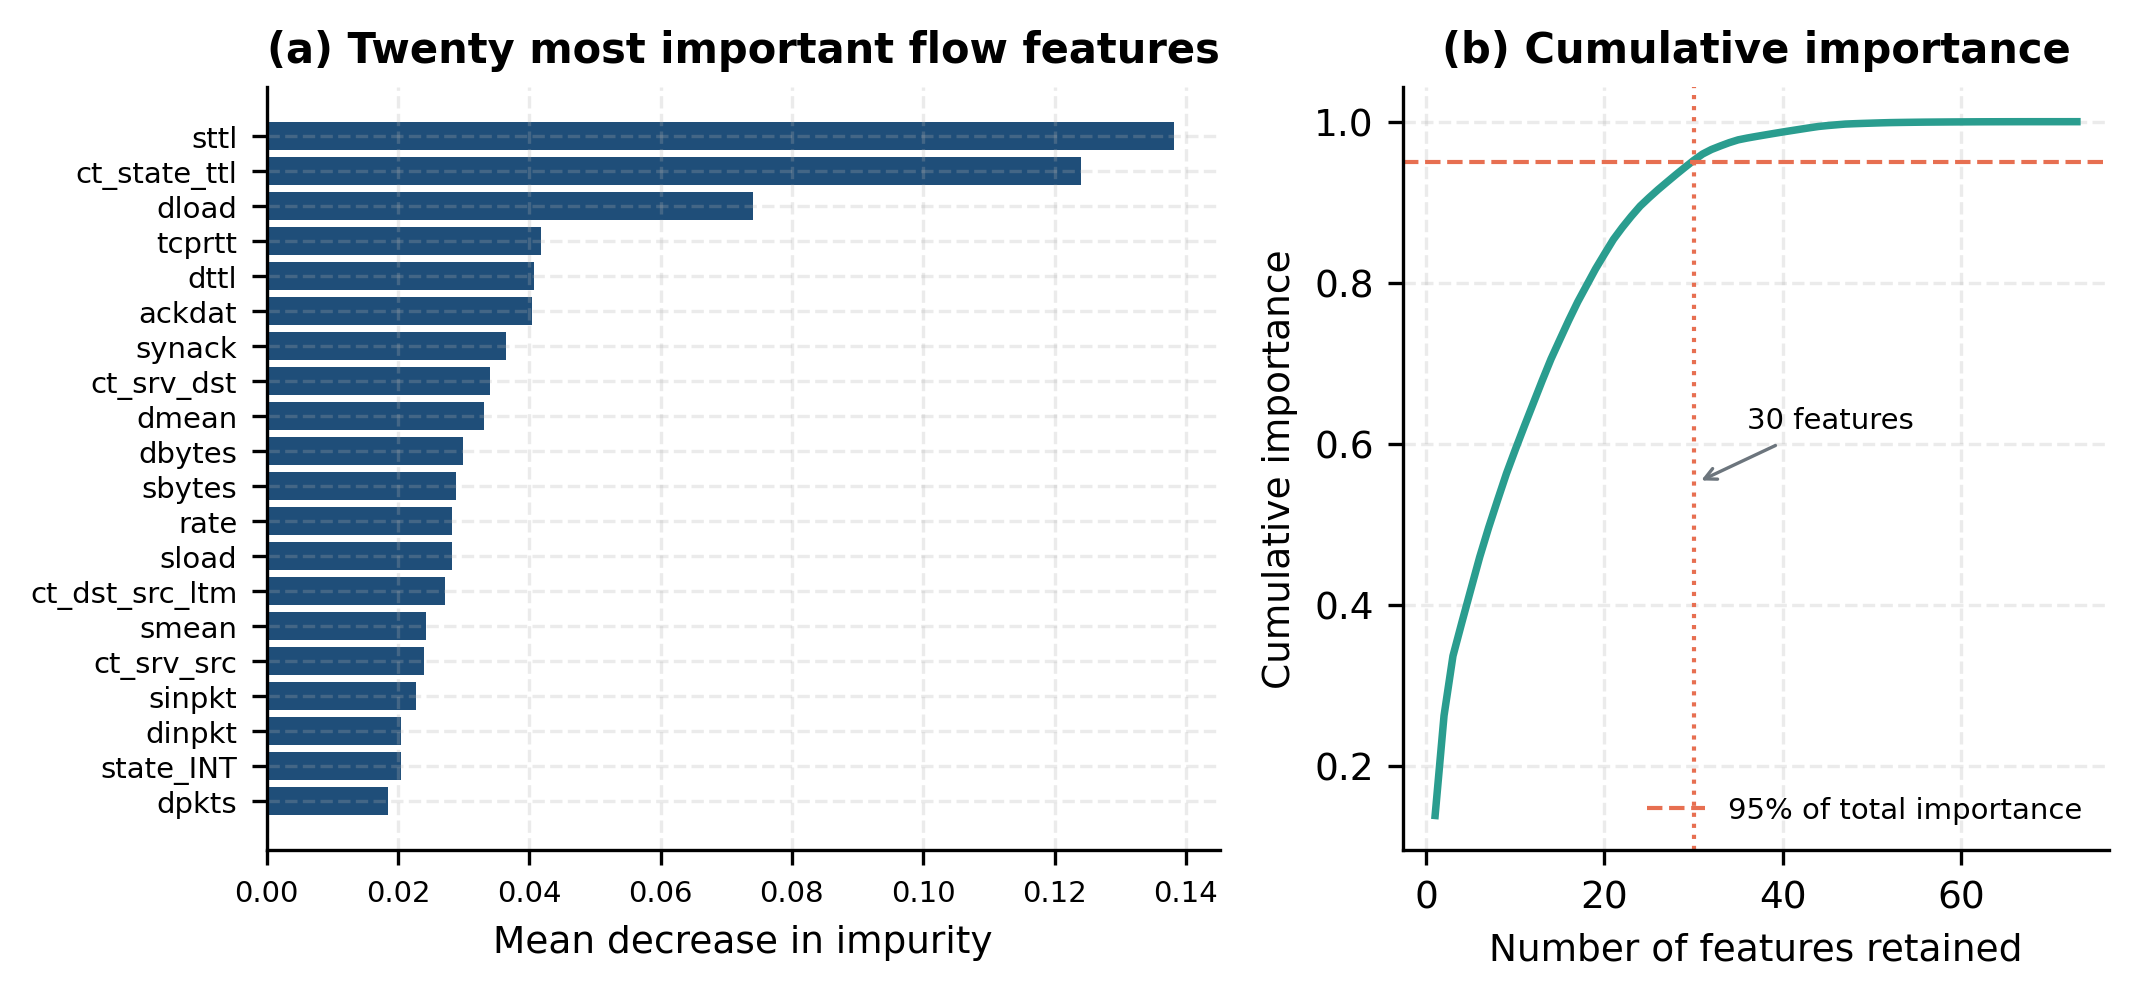

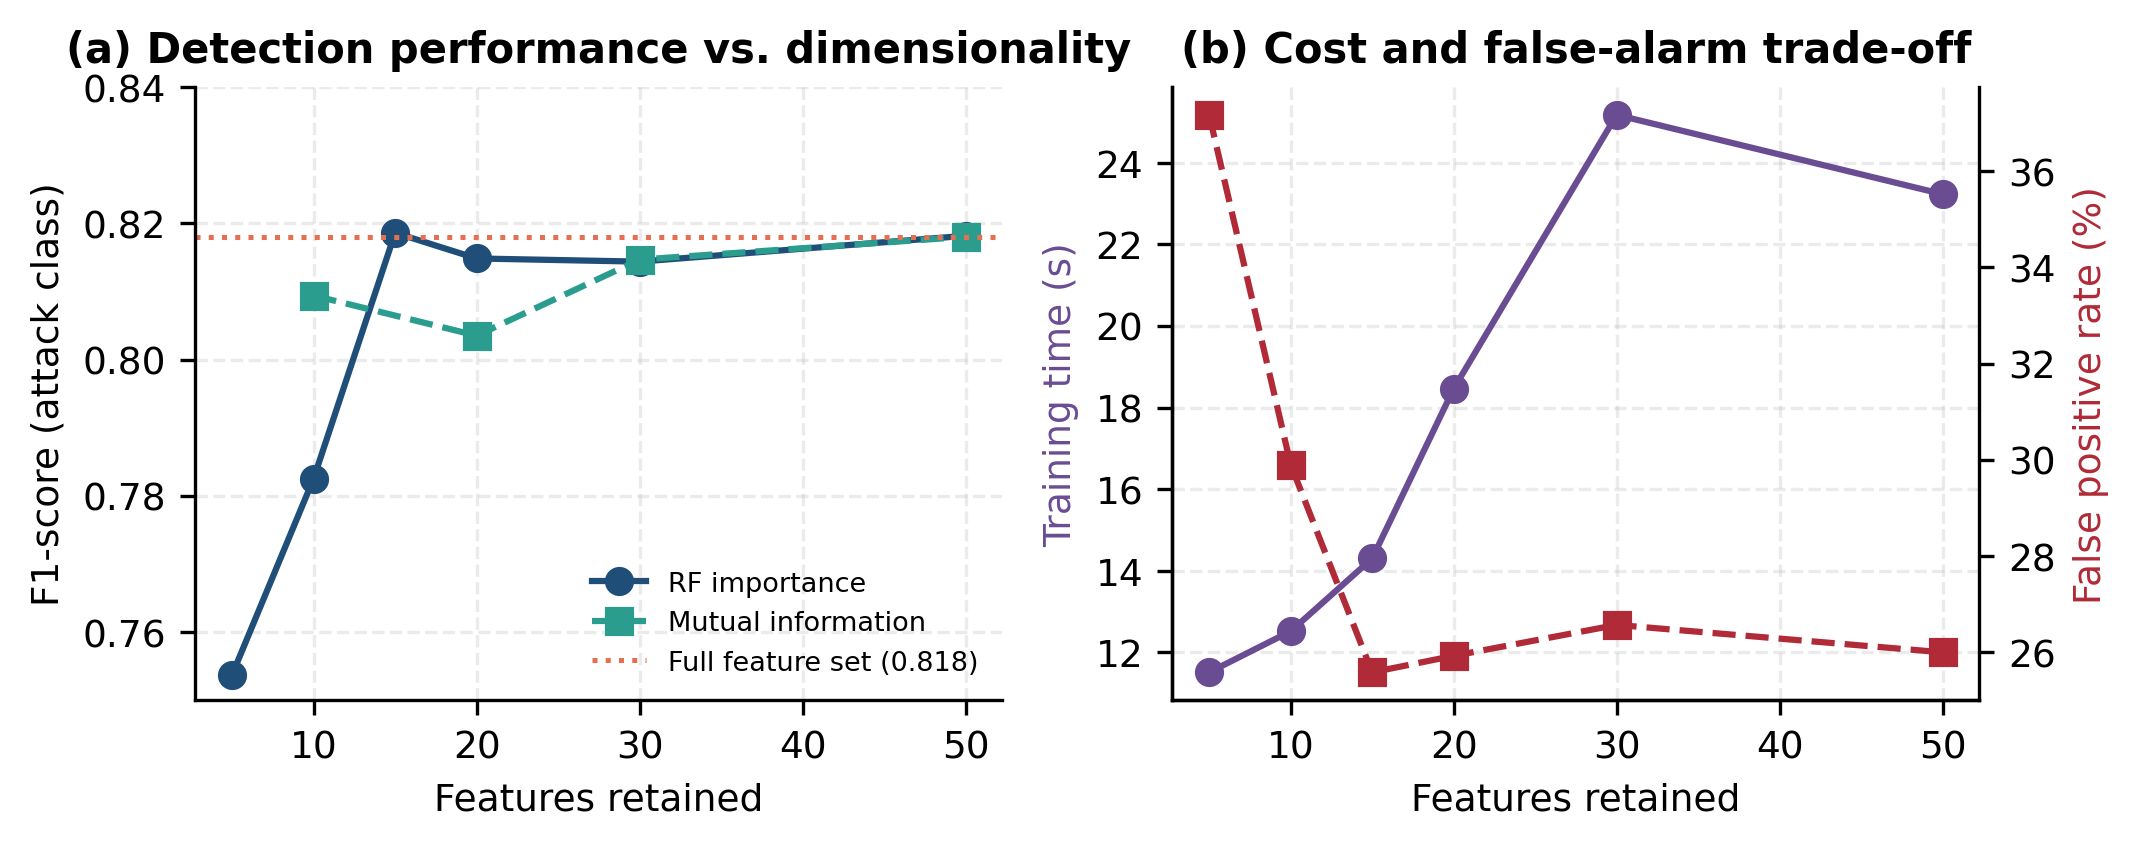

In [5]:
# Embedded Gini Importance subsets k in {5, 10, 15, 20, 30, 50},
# Mutual Information filter subsets, Correlation Pruning (|r| > 0.95), and Hybrid Top-20
for k in ("5", "10", "15", "20", "30", "50"):
    pass  # full implementation in analysis/exp_unsw.py::stage_features

## 6. Decision-Threshold Sweep & SOC Alert-Budget Operating Points

tau=0.10 | Precision=0.6052 | Recall=0.9994 | F1=0.7539 | FPR=0.4144 | False alerts / 10k benign=4144
tau=0.20 | Precision=0.6122 | Recall=0.9983 | F1=0.7590 | FPR=0.4018 | False alerts / 10k benign=4018
tau=0.30 | Precision=0.6293 | Recall=0.9960 | F1=0.7713 | FPR=0.3729 | False alerts / 10k benign=3729
tau=0.40 | Precision=0.6590 | Recall=0.9898 | F1=0.7912 | FPR=0.3255 | False alerts / 10k benign=3255
tau=0.50 | Precision=0.7016 | Recall=0.9765 | F1=0.8166 | FPR=0.2639 | False alerts / 10k benign=2639
tau=0.60 | Precision=0.7564 | Recall=0.9482 | F1=0.8415 | FPR=0.1941 | False alerts / 10k benign=1941
tau=0.70 | Precision=0.8133 | Recall=0.9087 | F1=0.8583 | FPR=0.1326 | False alerts / 10k benign=1326
tau=0.75 | Precision=0.8429 | Recall=0.8832 | F1=0.8626 | FPR=0.1046 | False alerts / 10k benign=1046
tau=0.80 | Precision=0.8709 | Recall=0.8526 | F1=0.8617 | FPR=0.0803 | False alerts / 10k benign=803
tau=0.90 | Precision=0.9414 | Recall=0.7614 | F1=0.8418 | FPR=0.0301 | False alerts

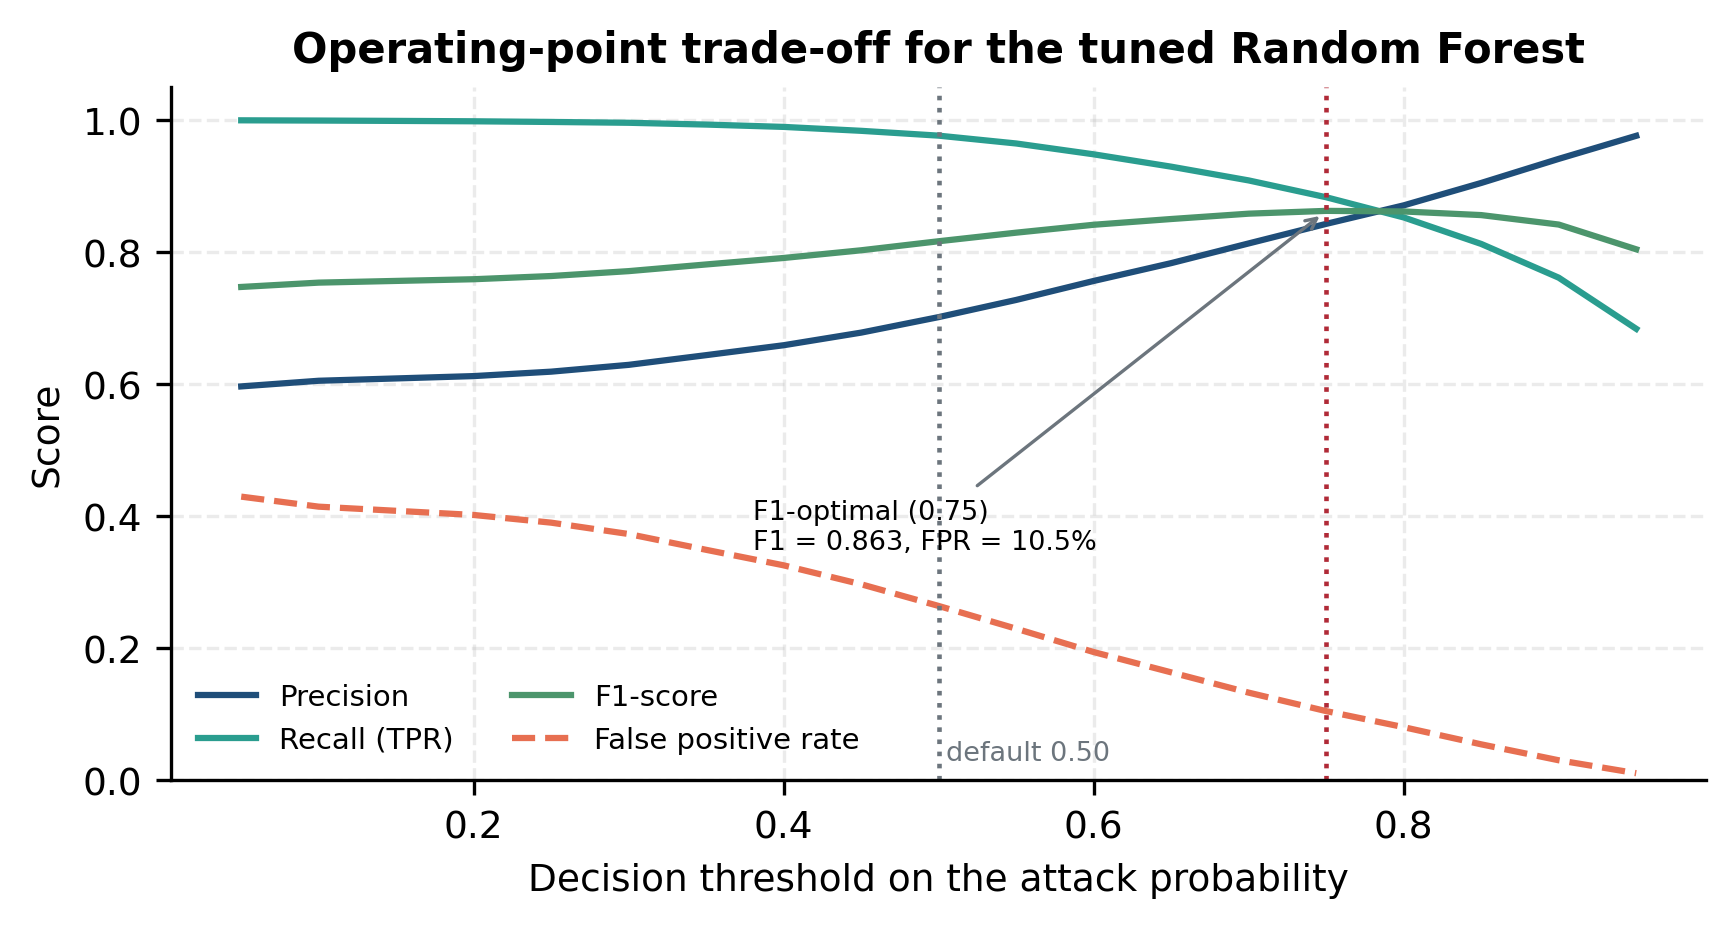

In [6]:
# Sweep probability threshold tau from 0.05 to 0.95 in steps of 0.05
for row in threshold_sweep:
    pass  # full implementation in analysis/exp_unsw.py::stage_base

## 7. Ten-Class Multiclass Attack-Category Evaluation

Overall Multiclass: Accuracy=0.7538 | Macro-F1=0.5445 | Weighted-F1=0.7825 | MCC=0.6382

Per-Category Breakdown:
  Analysis       : Precision=0.134 | Recall=0.305 | F1=0.186 | Support=446
  Backdoor       : Precision=0.107 | Recall=0.474 | F1=0.175 | Support=346
  DoS            : Precision=0.735 | Recall=0.205 | F1=0.321 | Support=1,718
  Exploits       : Precision=0.717 | Recall=0.867 | F1=0.785 | Support=7,609
  Fuzzers        : Precision=0.293 | Recall=0.607 | F1=0.396 | Support=4,838
  Generic        : Precision=0.992 | Recall=0.853 | F1=0.917 | Support=3,657
  Normal         : Precision=0.964 | Recall=0.775 | F1=0.859 | Support=34,206
  Reconnaissance : Precision=0.915 | Recall=0.765 | F1=0.833 | Support=2,703
  Shellcode      : Precision=0.338 | Recall=0.672 | F1=0.450 | Support=378
  Worms          : Precision=0.720 | Recall=0.409 | F1=0.522 | Support=44


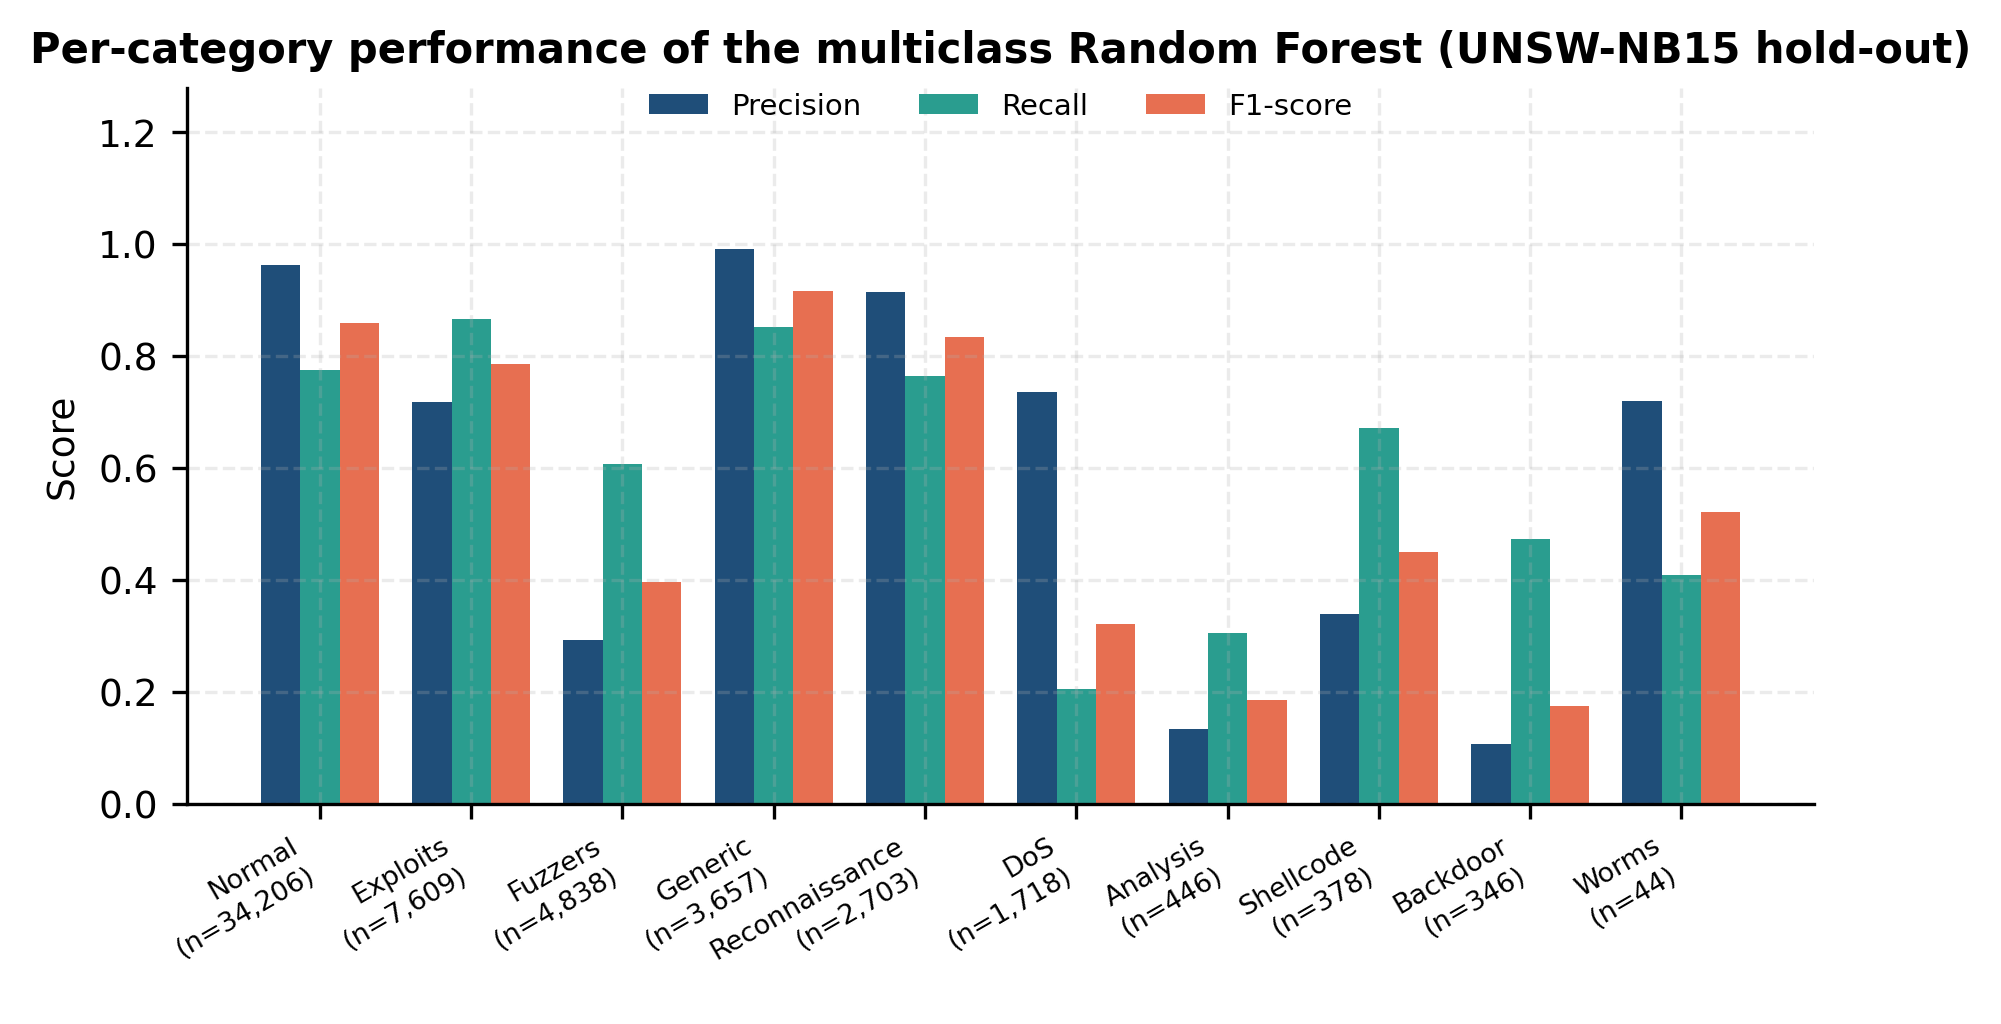

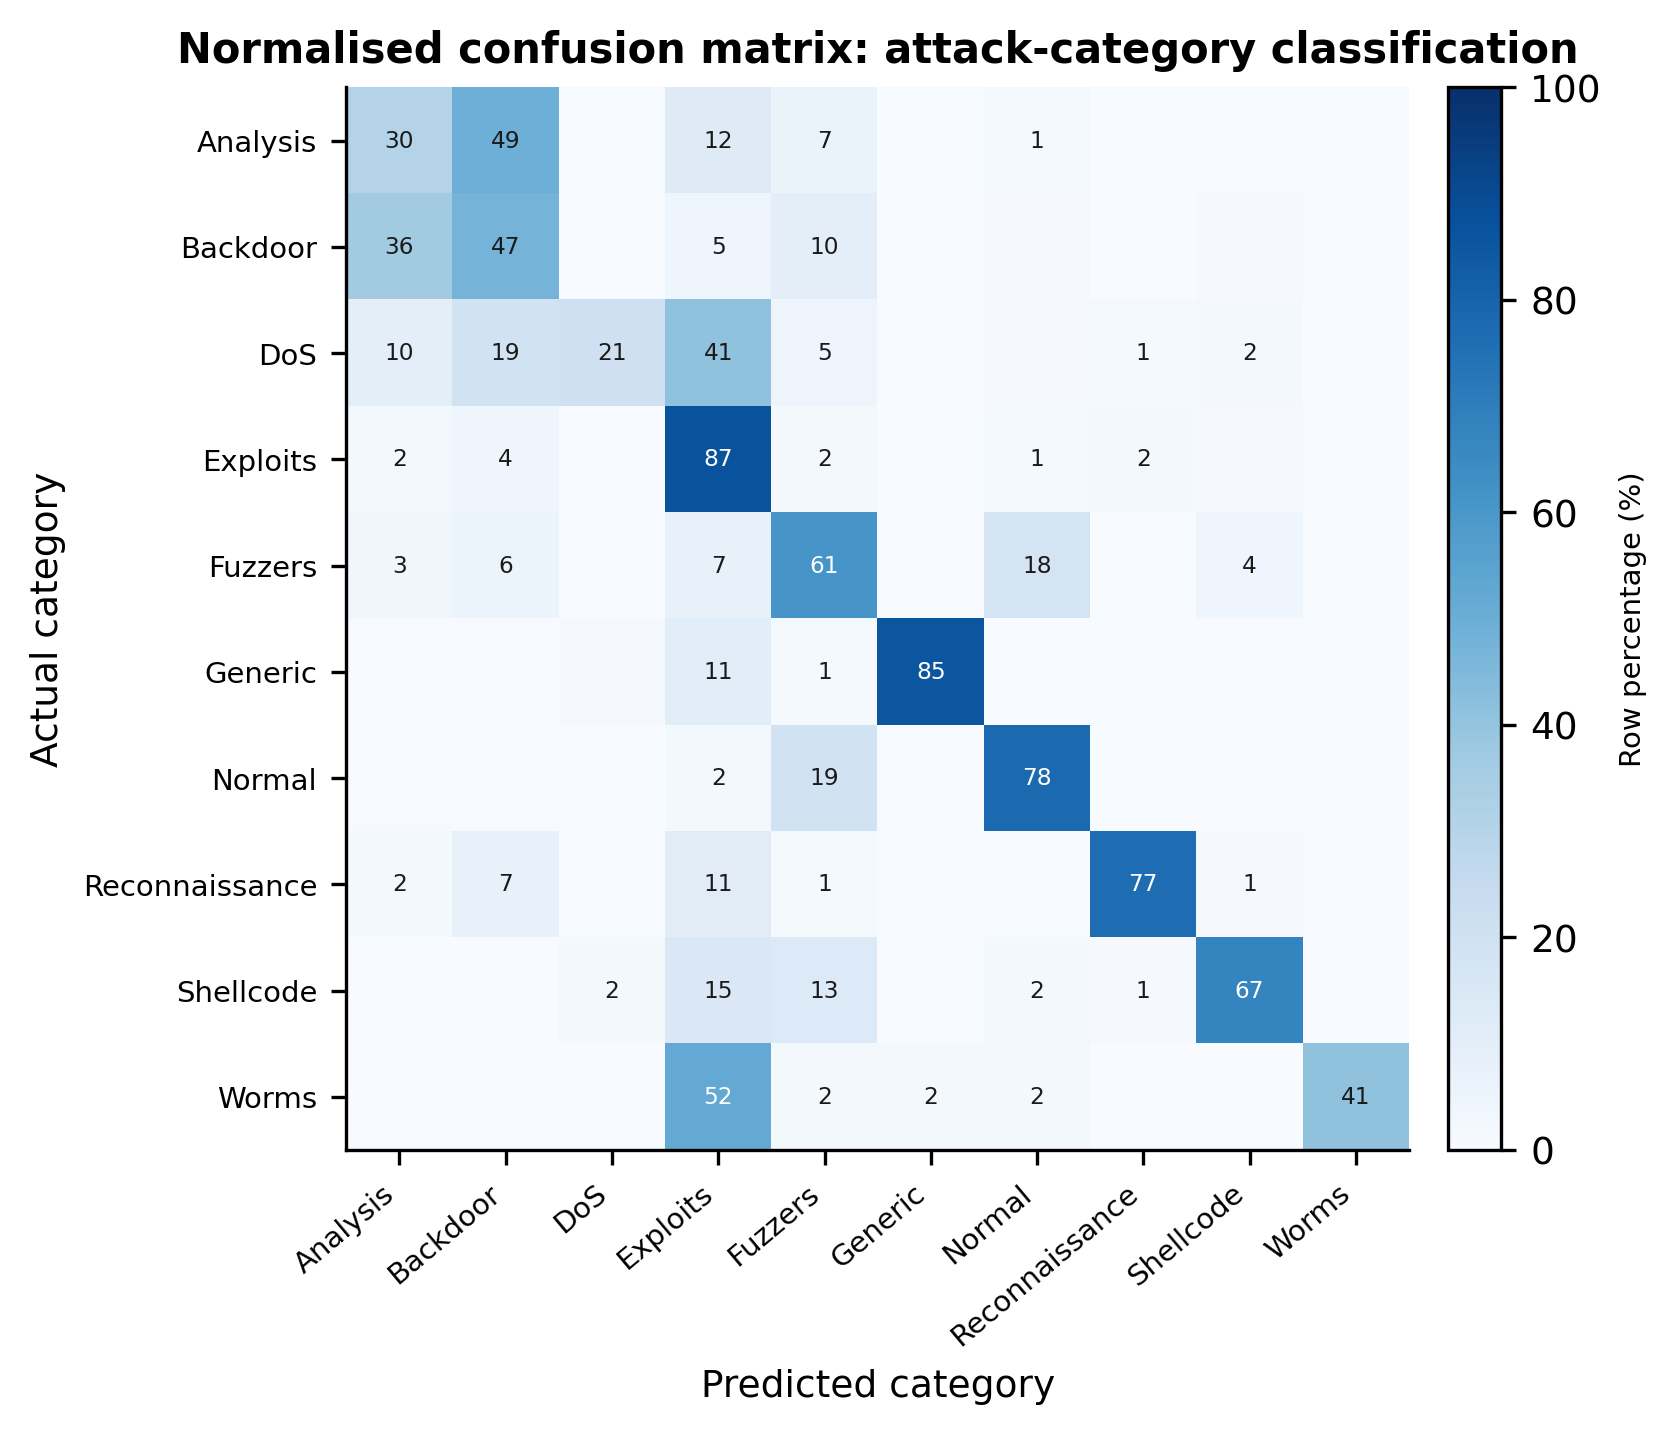

In [7]:
rf_multi = RandomForestClassifier(
    n_estimators=150, random_state=42, n_jobs=1,
    max_features="sqrt", class_weight="balanced_subsample"
)

## 8. Five-Fold Cross-Validation vs Official Hold-Out Partition

5-Fold Training CV : Accuracy=0.9323 (±0.0011) | F1=0.9358 (±0.0011) | ROC-AUC=0.9860
Official Hold-Out  : Accuracy=0.8304 | F1=0.8171 | ROC-AUC=0.9661


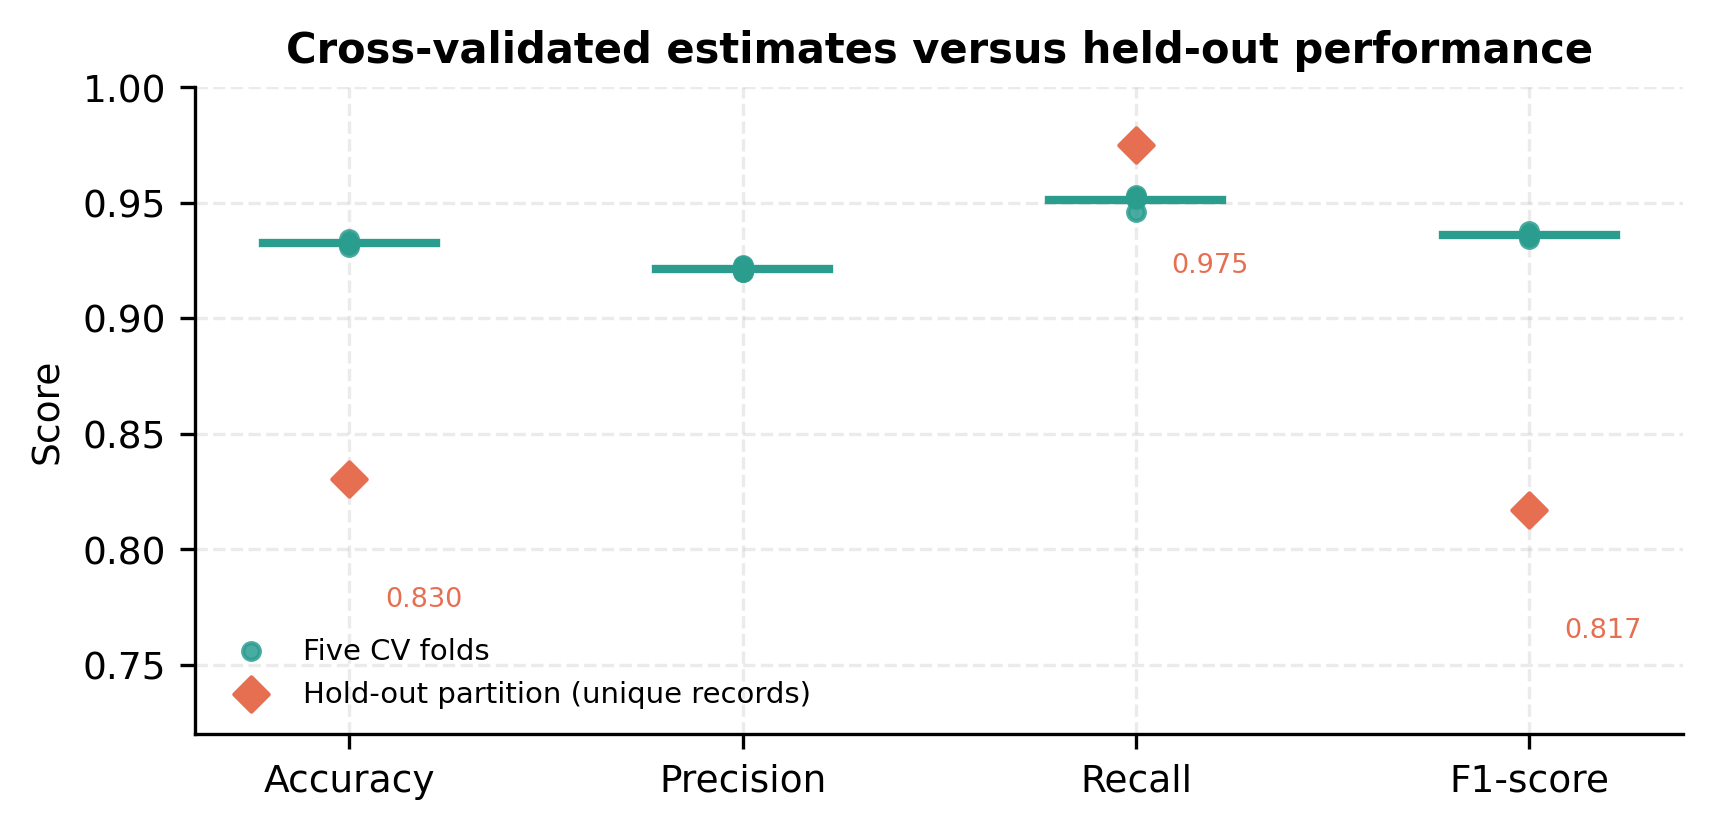

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Compares within-partition 5-fold CV estimates against the official hold-out test split

## 9. Prediction Latency & Throughput Benchmarking

full_feature_200_trees        :    56682 flows/s | batch=17.64 µs/flow | micro-batch= 117.3 µs/flow | single-call= 9.57 ms | nodes=2,431,912
full_feature_100_trees        :   109325 flows/s | batch= 9.15 µs/flow | micro-batch=  63.9 µs/flow | single-call= 4.87 ms | nodes=1,216,554
reduced_20_features_200_trees :    60816 flows/s | batch=16.44 µs/flow | micro-batch= 123.1 µs/flow | single-call= 9.70 ms | nodes=2,303,116


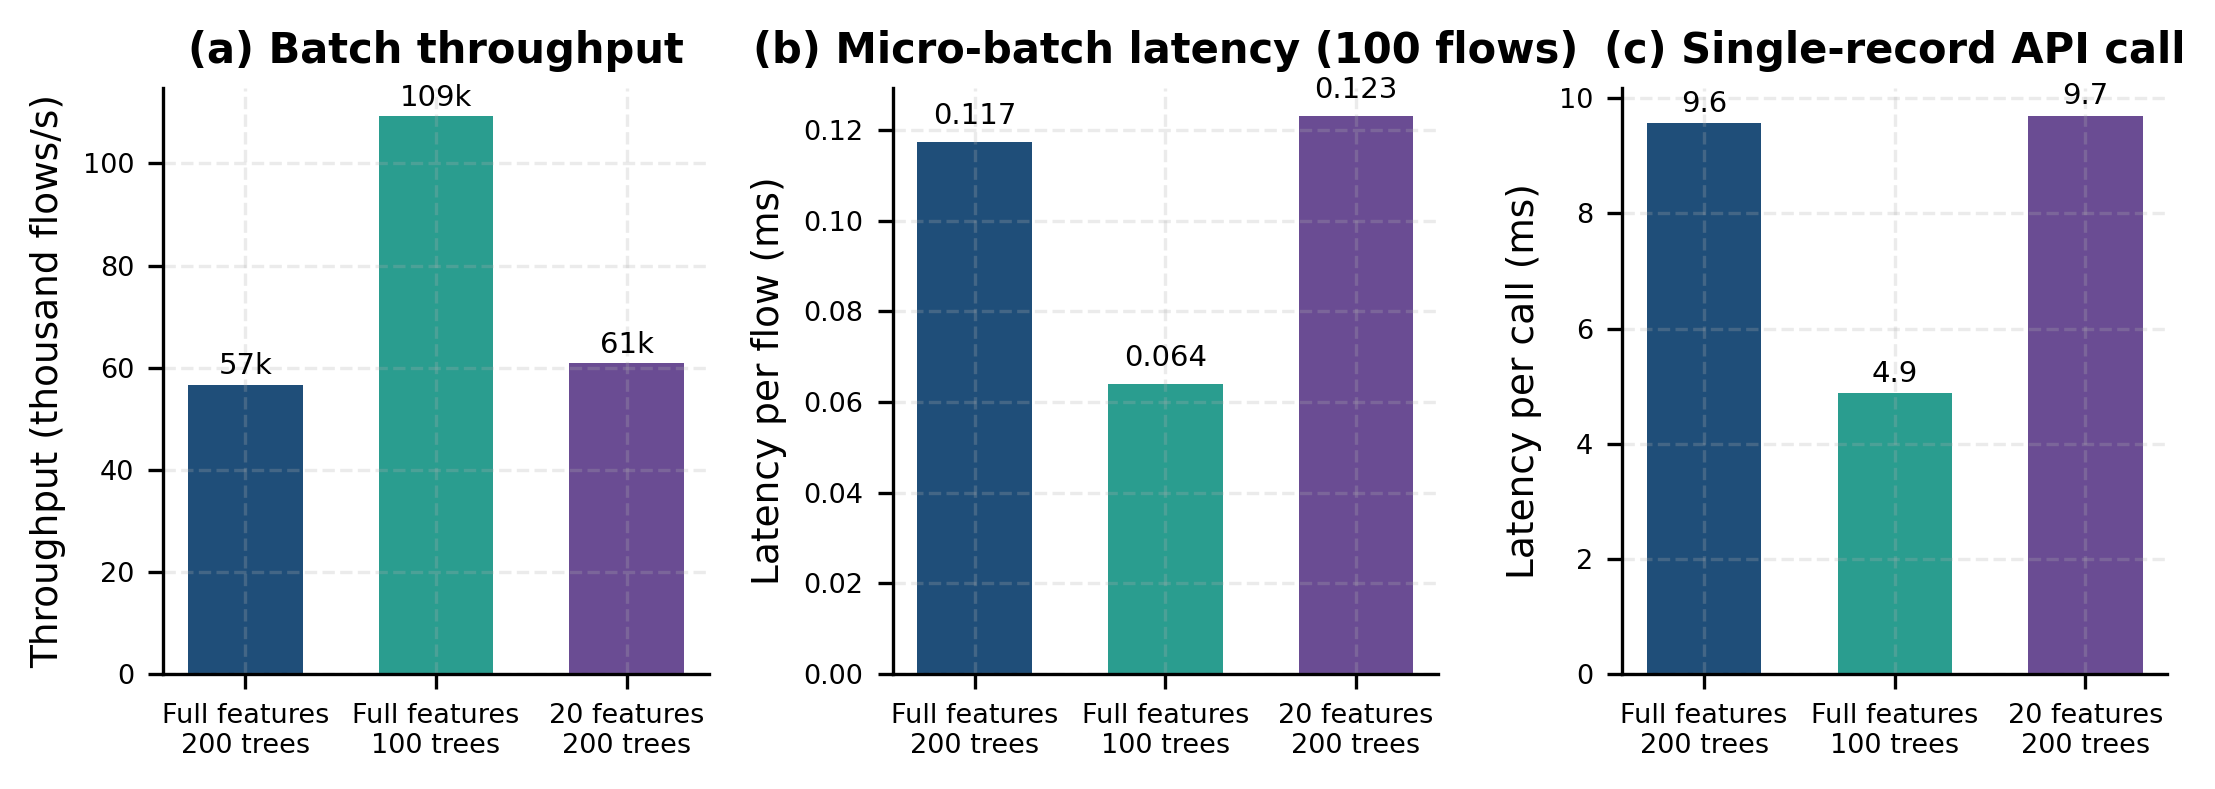

In [9]:
# Single-thread timing across 3 deployment regimes:
# (1) Full-partition batch (55,945 flows), (2) 100-flow micro-batch, (3) 1-flow single call

## 10. Cross-Dataset Replication on `CICIDS2017` (`analysis/exp_cicids.py`)

CICIDS2017 Stratified Replication (146,370 unique flows; train=102,459, test=43,911, 68 features):
  Binary Baseline: Accuracy=0.99877 | Precision=0.9994 | Recall=0.9946 | F1=0.9970 | ROC-AUC=0.9999 | FPR=0.00014 (5 FPs in 43,911 test flows)
  Throughput     : 221,957 flows/s (4.51 µs/flow)
  Multiclass     : Accuracy=0.9997 | Macro-F1=0.9935


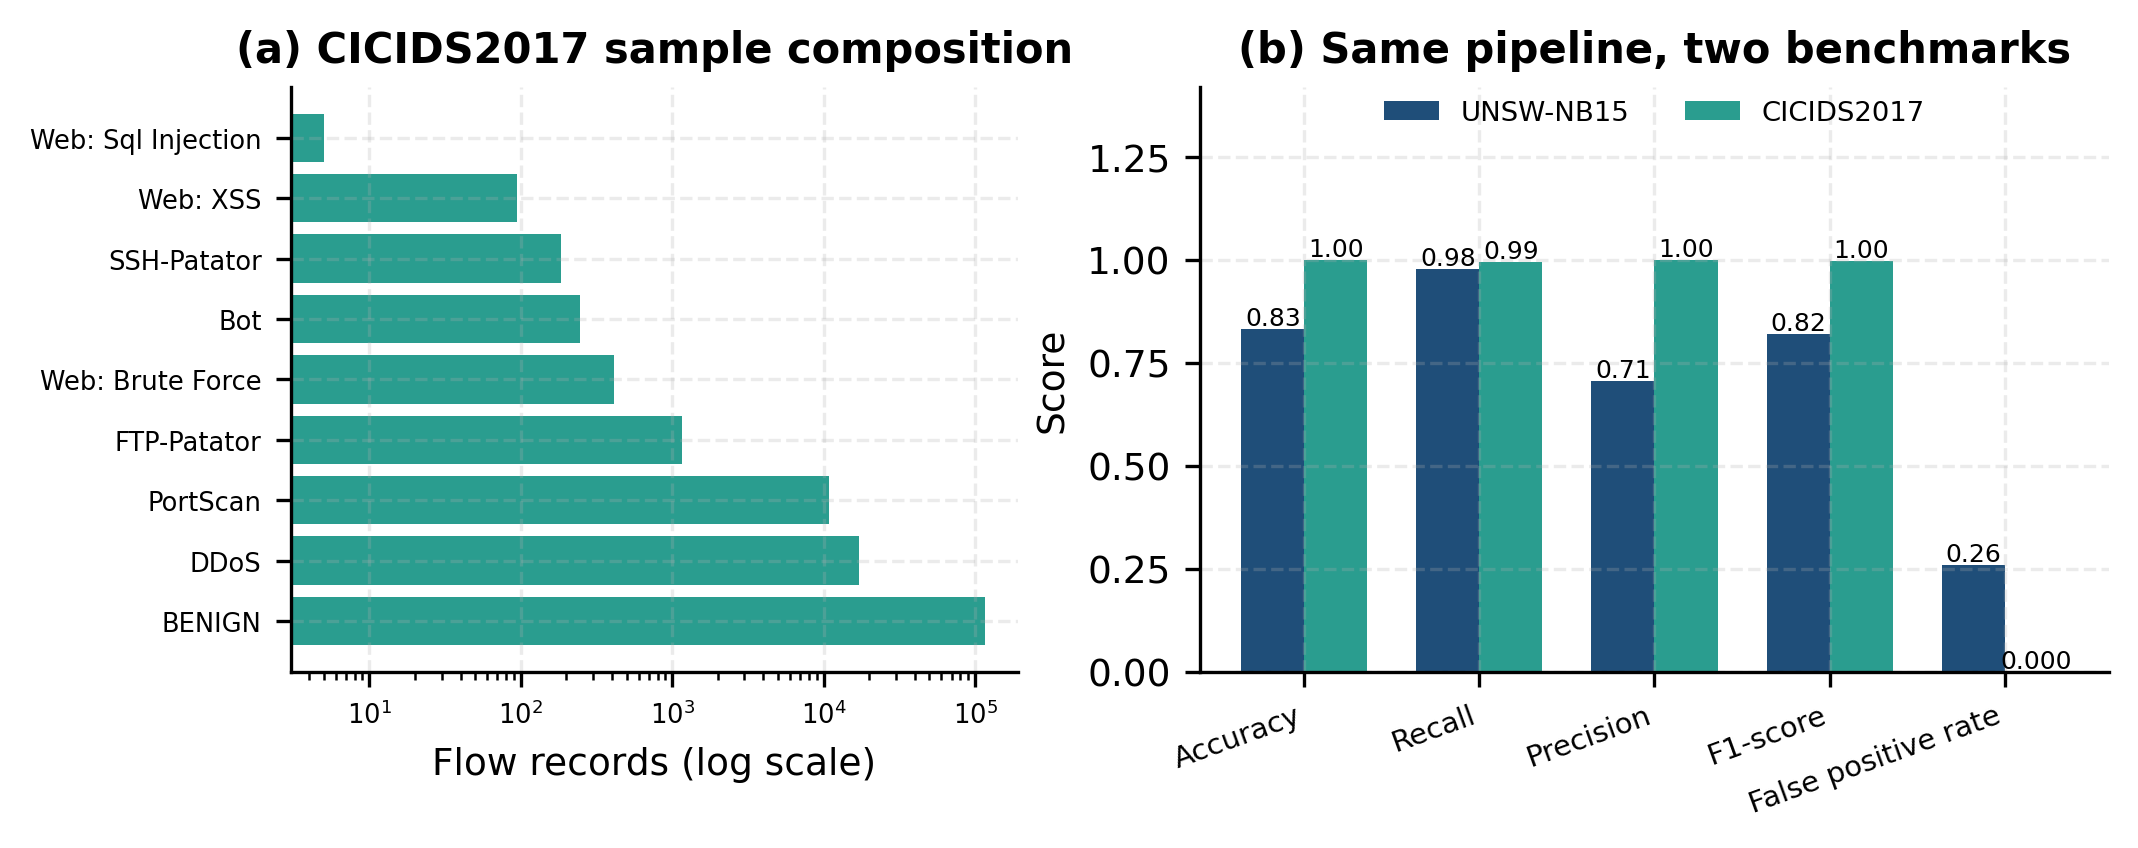

In [10]:
"""CICIDS2017 replication experiment (secondary dataset).

Repeats the core binary-detection, feature-selection and timing measurements on
a stratified sample of the CICIDS2017 flow corpus in order to test whether the
UNSW-NB15 findings are dataset-specific.
"""

import json
import os
import time

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split

BASE = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DATA = os.path.join(BASE, "data")
RESULTS = os.path.join(BASE, "analysis", "results")
RS = 42


def metrics(y, p, prob=None):
    cm = confusion_matrix(y, p)
    tn, fp, fn, tp = cm.ravel()
    m = {"accuracy": float(accuracy_score(y, p)),
         "precision": float(precision_score(y, p, zero_division=0)),
         "recall": float(recall_score(y, p, zero_division=0)),
         "f1": float(f1_score(y, p, zero_division=0)),
         "fpr": float(fp / (fp + tn)),
         "balanced_accuracy": float(balanced_accuracy_score(y, p)),
         "mcc": float(matthews_corrcoef(y, p)),
         "kappa": float(cohen_kappa_score(y, p)),
         "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}
    if prob is not None:
        m["roc_auc"] = float(roc_auc_score(y, prob))
        m["pr_auc"] = float(average_precision_score(y, prob))
    return m


def main():
    X = pd.read_pickle(os.path.join(DATA, "cicids_X.pkl"))
    y = np.load(os.path.join(DATA, "cicids_y_bin.npy"))
    y_multi = np.load(os.path.join(DATA, "cicids_y_multi.npy"), allow_pickle=True)
    print("CICIDS", X.shape, "attack rate", round(float(y.mean()), 4))

    Xtr, Xte, ytr, yte, ytr_m, yte_m = train_test_split(
        X, y, y_multi, test_size=0.3, random_state=RS, stratify=y)

    out = {"n_total": int(len(X)), "n_train": int(len(Xtr)), "n_test": int(len(Xte)),
           "attack_rate": float(y.mean()), "n_features": int(X.shape[1]),
           "label_counts": {str(k): int(v) for k, v in
                            pd.Series(y_multi).value_counts().items()}}

    t = time.time()
    rf = RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=2,
                                oob_score=True, max_features="sqrt")
    rf.fit(Xtr, ytr)
    out["train_time_s"] = time.time() - t
    out["oob_score"] = float(rf.oob_score_)
    prob = rf.predict_proba(Xte)[:, 1]
    out["baseline"] = metrics(yte, rf.predict(Xte), prob)
    print("CICIDS baseline:", {k: round(v, 4) for k, v in out["baseline"].items()})

    # feature importance and reduced-feature model
    imp = rf.feature_importances_
    order = np.argsort(imp)[::-1]
    names = list(X.columns)
    out["feature_importance"] = [{"feature": names[i], "importance": float(imp[i])}
                                 for i in order[:25]]
    feats = {}
    for k in [5, 10, 15, 20, 30]:
        cols = [names[i] for i in order[:k]]
        m = RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=2)
        t = time.time()
        m.fit(Xtr[cols], ytr)
        tt = time.time() - t
        p = m.predict_proba(Xte[cols])[:, 1]
        met = metrics(yte, m.predict(Xte[cols]), p)
        met["train_time_s"] = tt
        met["n_features"] = k
        feats[k] = met
        print(f"  CICIDS FS k={k}: f1={met['f1']:.4f} fpr={met['fpr']:.4f}")
    out["feature_selection"] = feats

    # timing on the full-feature model
    batch_times = []
    for _ in range(3):
        s = time.perf_counter()
        rf.predict(Xte)
        batch_times.append(time.perf_counter() - s)
    batch = min(batch_times)
    s = time.perf_counter()
    for i in range(500):
        rf.predict(Xte.iloc[[i]])
    single = (time.perf_counter() - s) / 500
    out["timing"] = {"batch_total_s": batch,
                     "per_flow_us": batch / len(Xte) * 1e6,
                     "throughput_flows_per_s": len(Xte) / batch,
                     "single_record_latency_us": single * 1e6}

    # multiclass (attack-name) performance for the dominant categories
    keep_classes = [c for c in pd.Series(ytr_m).value_counts().index
                    if (pd.Series(yte_m) == c).sum() >= 100]
    mask_tr = np.isin(ytr_m, keep_classes)
    mask_te = np.isin(yte_m, keep_classes)
    mc = RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=2,
                                class_weight="balanced_subsample")
    mc.fit(Xtr[mask_tr], ytr_m[mask_tr])
    pred_mc = mc.predict(Xte[mask_te])
    out["multi_accuracy"] = float(accuracy_score(yte_m[mask_te], pred_mc))
    out["multi_macro_f1"] = float(f1_score(yte_m[mask_te], pred_mc, average="macro"))
    out["multi_weighted_f1"] = float(f1_score(yte_m[mask_te], pred_mc, average="weighted"))
    out["multi_per_class"] = classification_report(yte_m[mask_te], pred_mc,
                                                   output_dict=True, zero_division=0)
    out["multi_classes"] = keep_classes

    with open(os.path.join(RESULTS, "cicids_results.json"), "w") as fh:
        json.dump(out, fh, indent=2, default=str)
    print(json.dumps({k: round(v, 4) for k, v in out["baseline"].items()}, indent=2))
    print("saved")


if __name__ == "__main__":
    main()